# Statistical Significance Tests — HetMap (revised paper)

Statistics-only notebook, in the style of `results_analysis.ipynb`, for the **revised** research questions.
Scores are handled as in the old notebook: loaded as fractions (0-1), displayed and written as **percentages**.
Tests: **Mann-Whitney U** (two-sided) with **Holm** correction and **Cliff's delta** effect sizes
(negligible < 0.147 <= small < 0.33 <= medium < 0.474 <= large).

| Section | RQ | What it does |
|---|---|---|
| 1 | - | USER CONFIG |
| 2 | - | Setup & load (selected 100-run snapshot + full 3,600-fit study) |
| 3 | RQ1 | File representations, feature-only MLP: W2V / N2V / UXC$_{ZS}$ / UXC$_{FT}$ |
| 4 | RQ2 | Graph configurations MLP / F / FM / FF / FFM per representation (line plots + tests) |
| 5 | RQ2 | Homophily x connectivity quadrant figures |
| 6 | RQ3 | Full controlled study: typed HGT, matched HGT, neighbour MLP, on/off x two schedules |
| 7 | - | Sanity checks against the supervisor's digest |

**Data:** the supervisor's frozen selection (`paper/review/data/selected` and `.../full/per-run.csv`).
It differs from `results/HGT_*` for A.UML (and is the data behind the revised paper's tables).

**Read before quoting a p-value**
- Mann-Whitney U is unpaired, but the runs of two compared conditions share their labelled splits. RQ3 therefore also reports a paired Wilcoxon signed-rank p and a 10-system sign test.
- Repeated splits overlap; they are not independent system replications.
- RQ1/RQ2 compare *selected historical configurations* whose classifiers, schedules and feature coverage differ. Their p-values describe those implementations, not isolated effects of one information source.
- Holm correction is applied per metric over every test in a table.

## 1. USER CONFIG

In [1]:
import numpy as np
from matplotlib.ticker import MaxNLocator
import pandas as pd
from pathlib import Path
from scipy.stats import ranksums
import shutil, warnings
from scipy.stats import mannwhitneyu, wilcoxon, binomtest
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations

warnings.filterwarnings("ignore")
plt.rcParams["text.usetex"] = True
try:  # fall back to mathtext if no LaTeX installation is available
    _f = plt.figure(); _f.text(0.5, 0.5, r"$\langle k \rangle$"); _f.canvas.draw(); plt.close(_f)
except Exception as _e:
    print("LaTeX unavailable, using mathtext:", type(_e).__name__)
    plt.rcParams["text.usetex"] = False
sns.set_theme(
    style="ticks",
    rc={
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.spines.left": True,
        "axes.spines.bottom": True,
        "axes.edgecolor": "black",
        "axes.linewidth": 1,
        "xtick.bottom": True,
        "ytick.left": True,
        "xtick.major.size": 3,
        "ytick.major.size": 3,
        "xtick.major.width": 1,
        "ytick.major.width": 1,
        "axes.grid": True,
        "axes.grid.axis": "x",
        "grid.alpha": 0.7,
        "grid.linestyle": "-",
        "grid.linewidth": 0.7,
    }
)
plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "black",
    "axes.linewidth": 1,
    "xtick.major.size":4,
    "ytick.major.size": 4,
    "xtick.major.width": 1,
    "ytick.major.width": 1,
    "xtick.color": "black",
    "ytick.color": "black",
    "axes.axisbelow": True,
    "grid.alpha": 0.4,
    "grid.linestyle": "-",
    "grid.linewidth": 0.5,
})
ALPHA = 0.05

In [2]:
# ── paths: resolve from wherever this notebook lives (repo root or results/) ──
def _find_root(start=None):
    p = Path(start or Path.cwd()).resolve()
    for q in [p, *p.parents]:
        if (q / "results").is_dir() and ((q / "llm_based changes").is_dir() or (q / "hetmap-local-review-20261005").is_dir()):
            return q
    raise FileNotFoundError("Could not find the HetMap folder (needs results/ and the review package).")

ROOT = _find_root()
RESULTS_BASE = ROOT / "results"
REVIEW_DATA = next(p for p in [ROOT / "llm_based changes/paper/review/data",
                               ROOT / "hetmap-local-review-20261005/paper/review/data"] if p.is_dir())
SELECTED_DIR   = REVIEW_DATA / "selected"
FULL_PER_RUN   = REVIEW_DATA / "full" / "per-run.csv"
GRAPH_PROPS    = next(p for p in [RESULTS_BASE / "graph_properties.csv",
                                  ROOT / "llm_based changes/results/graph_properties.csv"] if p.exists())
STATS_DIR = RESULTS_BASE / "Statiscal_Test"      # same folder as before
FIG_DIR   = RESULTS_BASE / "Figures"
STATS_DIR.mkdir(exist_ok=True); FIG_DIR.mkdir(exist_ok=True)

# Existing files that a new output would overwrite are copied here first (never deleted).
BACKUP_TAG = "previous_version_20261005"
def _backup(path):
    """Copy a pre-existing file into previous_version_*/ once. Files this notebook wrote itself
    (listed in .stats_notebook_outputs.txt) are never treated as 'previous versions'."""
    path = Path(path)
    manifest = path.parent / ".stats_notebook_outputs.txt"
    mine = set(manifest.read_text().split()) if manifest.exists() else set()
    if path.exists() and path.name not in mine:
        bdir = path.parent / BACKUP_TAG
        bdir.mkdir(exist_ok=True)
        if not (bdir / path.name).exists():
            shutil.copy2(path, bdir / path.name)
    if path.name not in mine:
        with open(manifest, "a") as fh:
            fh.write(path.name + chr(10))

def fig_path(name):
    p = FIG_DIR / name
    _backup(p)
    return p

def save_stats(df, name):
    p = STATS_DIR / name
    _backup(p)
    df.to_csv(p, index=False)
    print(f"saved {p.relative_to(ROOT)}  ({len(df)} rows)")

print("ROOT         :", ROOT)
print("REVIEW_DATA  :", REVIEW_DATA.relative_to(ROOT))
print("GRAPH_PROPS  :", GRAPH_PROPS.relative_to(ROOT))

DATASETS = ['A.UML', 'C.Img', 'JabRef', 'Lucene', 'SH-3D', 'T.Mates', 'Bash', 'HDF', 'Chrome', 'HDC']   # None = all ten systems
SCORE_COLS = ['f1_macro', 'f1_micro']
DATASET_ORDER = ['A.UML', 'C.Img', 'JabRef', 'Lucene', 'SH-3D', 'T.Mates', 'Bash', 'HDF', 'Chrome', 'HDC']
SYS_RENAME = {'Jabref': 'JabRef', 'TeamMates': 'T.Mates'}

# ── RQ1: no graph, feature is the variable (selected feature-only MLP results) ──
RQ1_METHODS = [
    ('N2V', 'MLP', 'N2V'),
    ('W2V', 'MLP', 'W2V'),
    ('UXC', 'ZS',  'UXC$_{ZS}$'),
    ('UXC', 'MLP', 'UXC$_{FT}$'),
]
# ── RQ2: feature x graph configuration (selected 100-run configuration results) ──
RQ2_METHODS = [
    ('W2V', 'MLP', 'W2V'),        ('W2V', 'F', 'W2V$_{F}$'),   ('W2V', 'FM', 'W2V$_{FM}$'),
    ('W2V', 'FF',  'W2V$_{FF}$'), ('W2V', 'FFM', 'W2V$_{FFM}$'),
    ('N2V', 'MLP', 'N2V'),        ('N2V', 'F', 'N2V$_{F}$'),   ('N2V', 'FM', 'N2V$_{FM}$'),
    ('N2V', 'FF',  'N2V$_{FF}$'), ('N2V', 'FFM', 'N2V$_{FFM}$'),
    ('UXC', 'MLP', 'UXC$_{FT}$'), ('UXC', 'F', 'UXC$_{F}$'),   ('UXC', 'FM', 'UXC$_{FM}$'),
    ('UXC', 'FF',  'UXC$_{FF}$'), ('UXC', 'FFM', 'UXC$_{FFM}$'),
]
# Tests are run within one representation (MLP vs F vs FM vs FF vs FFM); cross-representation
# comparisons belong to RQ1. Pair order matches the old notebook (first-named = lower graph level).
RQ2_FAMILIES = {
    'W2V': ['W2V', 'W2V$_{F}$', 'W2V$_{FM}$', 'W2V$_{FF}$', 'W2V$_{FFM}$'],
    'N2V': ['N2V', 'N2V$_{F}$', 'N2V$_{FM}$', 'N2V$_{FF}$', 'N2V$_{FFM}$'],
    'UXC$_{FT}$': ['UXC$_{FT}$', 'UXC$_{F}$', 'UXC$_{FM}$', 'UXC$_{FF}$', 'UXC$_{FFM}$'],
}

METHOD_PALETTE = {
    'N2V': '#B2DF8A', 'W2V': '#A6CEE3', 'UXC$_{ZS}$': '#FB9A99', 'UXC$_{FT}$': '#CAB2D6',
    'W2V$_{F}$':   '#8BC1DE', 'W2V$_{FM}$':  '#68ADD1', 'W2V$_{FF}$':  '#438FB9', 'W2V$_{FFM}$': '#216FA5',
    'N2V$_{F}$':   '#94CC70', 'N2V$_{FM}$':  '#72B850', 'N2V$_{FF}$':  '#519B34', 'N2V$_{FFM}$': '#34751E',
    'UXC$_{F}$':   '#B898CA', 'UXC$_{FM}$':  '#9B73B4', 'UXC$_{FF}$':  '#7B5595', 'UXC$_{FFM}$': '#5C3974',
}
RQ1_METHOD_ORDER = ['N2V', 'W2V', 'UXC$_{ZS}$', 'UXC$_{FT}$']

# ── RQ3: the 3,600-fit full study ──
SCHEDULES = ['supervised190', 'self190']
RQ3_COMPARISONS = {   # family -> (treatment condition template, control condition template)
    'Typed HGT':     ('hgt_directed_typed_{s}_on',         'hgt_directed_typed_{s}_off'),
    'Matched HGT':   ('hgt_bidirectional_untyped_{s}_on',  'hgt_bidirectional_untyped_{s}_off'),
    'Neighbour MLP': ('mlp_{s}_undirected',                'mlp_{s}_own'),
}

ROOT         : C:\Users\JABEERAK\Architecture_Recovery\HetMap
REVIEW_DATA  : llm_based changes\paper\review\data
GRAPH_PROPS  : results\graph_properties.csv


## 2. Setup & load

In [8]:
_cache = {}

def _ordered_datasets(ds_iterable):
    """Datasets sorted by DATASET_ORDER; unknown ones are appended, not dropped."""
    ds_set = set(ds_iterable)
    return [d for d in DATASET_ORDER if d in ds_set] + sorted(ds_set - set(DATASET_ORDER))

def load_selected(rep, cond, label):
    """One selected 100-run cell (all systems). Percent values are converted to fractions, as in the old notebook."""
    key = (rep, cond)
    if key not in _cache:
        folder = SELECTED_DIR / rep / cond
        frames = []
        for p in sorted(folder.glob('*.csv')):
            df = pd.read_csv(p)
            df['dataset'] = SYS_RENAME.get(p.stem, p.stem)
            frames.append(df)
        df = pd.concat(frames, ignore_index=True)
        for col in SCORE_COLS:
            assert df[col].median() > 1, f'{rep}/{cond}: scores do not look like percentages'
            df[col] = df[col] / 100.0
        _cache[key] = df
    df = _cache[key].copy()
    if DATASETS:
        df = df[df['dataset'].isin(DATASETS)]
    df['_label'] = label
    return df

def load_group(method_list):
    return {label: load_selected(rep, cond, label) for rep, cond, label in method_list}

RQ1 = load_group(RQ1_METHODS)
RQ2 = load_group(RQ2_METHODS)

for grp in (RQ1, RQ2):
    for label, df in grp.items():
        n = df.groupby('dataset').size()
    assert len(n) == 10 and (n == 100).all(), f'{label}: expected 10 systems x 100 runs, got {n.to_dict()}'
print('RQ1:', list(RQ1), '\nRQ2:', len(RQ2), 'conditions; all cells = 10 systems x 100 runs')

# ── full study (RQ3): final-stage rows only, scores kept in percent (pp effects) ──
full_all = pd.read_csv(FULL_PER_RUN)
full_all['dataset'] = full_all['system'].replace(SYS_RENAME)
full = full_all[full_all['stage'] == 'final'].copy()
assert len(full) == 3600 and full.groupby(['dataset', 'condition']).size().eq(30).all()
print('RQ3: 3,600 final-stage fits; 30 (3 seeds x 10 splits) per system and condition')

RQ1: ['N2V', 'W2V', 'UXC$_{ZS}$', 'UXC$_{FT}$'] 
RQ2: 15 conditions; all cells = 10 systems x 100 runs
RQ3: 3,600 final-stage fits; 30 (3 seeds x 10 splits) per system and condition


### Statistical helpers

In [9]:
def cliff_delta(a, b) -> float:
    a, b = np.asarray(a), np.asarray(b)
    return (np.sum(a[:, None] > b[None, :]) - np.sum(a[:, None] < b[None, :])) / (len(a) * len(b))

def interpret_cliff(d: float) -> str:
    ad = abs(d)
    if ad < 0.147: return 'negligible'
    if ad < 0.330: return 'small'
    if ad < 0.474: return 'medium'
    return 'large'

def mw_test(a, b):
    """Mann-Whitney U (two-sided, asymptotic with tie correction) + Cliff's delta."""
    res = mannwhitneyu(a, b, alternative='two-sided', method='asymptotic')
    cd = cliff_delta(a, b)
    return res.statistic, res.pvalue, cd, interpret_cliff(cd)

def holm(pvals):
    """Holm-adjusted p-values, in the original order."""
    p = np.asarray(pvals, dtype=float)
    order = np.argsort(p)
    adj = np.empty_like(p)
    prev = 0.0
    for rank, idx in enumerate(order):
        prev = min(max((len(p) - rank) * p[idx], prev), 1.0)
        adj[idx] = prev
    return adj

STAT_COLS = ['metric', 'comparison', 'method_a', 'method_b', 'dataset',
             'method_a med%', 'method_b med%', 'median_diff', 'median_diff%',
             'method_a IQR', 'method_b IQR', 'stat', 'p', 'p_holm',
             'sig', 'sig_holm', "Cliff's d", 'effect']

def stat_table(data: dict, metrics: list, pairs=None):
    """
    Mann-Whitney U + Cliff's delta for every pair in `pairs` (default: all pairs of `data`),
    per dataset (DATASET_ORDER) and pooled. Same columns as the old notebook's stat_table
    (median_diff is a fraction; median_diff% is in percentage points; method_a minus method_b).
    Holm correction is applied within each metric over every row of the table.
    """
    pairs = list(pairs) if pairs is not None else list(combinations(data.keys(), 2))
    out = []
    for metric in metrics:
        rows = []
        for la, lb in pairs:
            df_a, df_b = data[la], data[lb]
            groups = [(ds, df_a.loc[df_a['dataset'] == ds, metric].dropna().values,
                           df_b.loc[df_b['dataset'] == ds, metric].dropna().values)
                      for ds in _ordered_datasets(set(df_a['dataset']) & set(df_b['dataset']))]
            groups.append(('ALL (pooled)', df_a[metric].dropna().values, df_b[metric].dropna().values))
            for ds, a, b in groups:
                if len(a) < 2 or len(b) < 2:
                    continue
                stat, p, cd, interp = mw_test(a, b)
                med_a, med_b = np.median(a), np.median(b)
                q1a, q3a = np.percentile(a, [25, 75]); q1b, q3b = np.percentile(b, [25, 75])
                rows.append({
                    'metric': metric, 'comparison': f'{la} vs {lb}', 'method_a': la, 'method_b': lb, 'dataset': ds,
                    'method_a med%': round(med_a * 100, 1), 'method_b med%': round(med_b * 100, 1),
                    'median_diff': round(med_a - med_b, 4), 'median_diff%': round((med_a - med_b) * 100, 1),
                    'method_a IQR': round(q3a - q1a, 4), 'method_b IQR': round(q3b - q1b, 4),
                    'stat': round(stat, 3), '_p': p, "Cliff's d": round(cd, 3), 'effect': interp,
                })
        adj = holm([r['_p'] for r in rows])
        for r, pa in zip(rows, adj):
            r['sig'] = '*' if r['_p'] < ALPHA else ''
            r['sig_holm'] = '*' if pa < ALPHA else ''
            r['p'] = f"{r.pop('_p'):.4f}"
            r['p_holm'] = f"{pa:.4f}"
        out.extend(rows)
    return pd.DataFrame(out)[STAT_COLS]

def summary_table_(data: dict, metric: str = 'f1_micro'):
    """Median score x100 per method (rows) and dataset (columns, DATASET_ORDER)."""
    all_ds = _ordered_datasets(ds for df in data.values() for ds in df['dataset'].unique())
    rows = []
    for label, df in data.items():
        row = {'method': label}
        for ds in all_ds:
            v = df.loc[df['dataset'] == ds, metric].dropna().values
            row[ds] = round(np.median(v) * 100, 1) if len(v) else np.nan
        rows.append(row)
    return pd.DataFrame(rows).set_index('method')[all_ds]

def bold_max(s):
    return ['font-weight:bold' if v == s.max() else '' for v in s]

### Plotting helpers (from the old notebook)

In [10]:
TAB10 = plt.get_cmap('tab10').colors
def method_colors(labels):
    return {l: METHOD_PALETTE.get(l, TAB10[i % 10]) for i, l in enumerate(labels)}

def boxplot_group(data: dict, metric: list, title: str, save_path=None):
    """
    Boxplot for a group (seaborn). Scores multiplied by 100 for display.

    `metric` is a list of metric names; one subplot is drawn per metric,
    arranged as:
      1 metric  -> 1x1
      2 metrics -> 1x2
      3 metrics -> 1x3
      4 metrics -> 2x2
      >4        -> grid with up to 3 columns
    """
    metrics = list(metric)
    n = len(metrics)

    if n <= 1:
        nrows, ncols = 1, 1
    elif n == 2:
        nrows, ncols = 2, 1
    elif n == 3:
        nrows, ncols = 1, 3
    elif n == 4:
        nrows, ncols = 2, 2
    else:
        ncols = 3
        nrows = int(np.ceil(n / ncols))

    labels = list(data.keys())
    colors = method_colors(labels)

    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(max(3, len(labels)) * ncols, 2.5 * nrows),
        squeeze=False, sharex=True, sharey=False
    )
    axes = axes.flatten()

    for ax_i, m in enumerate(metrics):
        ax = axes[ax_i]

        long_df = pd.concat([
            pd.DataFrame({'label': l, 'value': data[l][m].dropna().values * 100})
            for l in labels
        ], ignore_index=True)

        sns.boxplot(
            data=long_df, x='label', y='value', hue='label',
            order=labels, hue_order=labels,
            palette=colors, ax=ax,
            linewidth=0.8, medianprops=dict(color='black', linewidth=0.7),
            legend=False
        )
        for patch in ax.patches:
            patch.set_alpha(0.95)

        ax.set_xlabel('')
        ax.set_ylabel(' ')
        ax.set_title(m.replace('_', ' ').capitalize() if n > 1 else title)
        ax.tick_params(axis='x', rotation=0)

        for i, l in enumerate(labels):
            v = long_df.loc[long_df['label'] == l, 'value'].values
            ax.text(i, np.median(v) + 0.5, f' {np.median(v):.1f}', va='bottom', fontsize=8)

    for ax_i in range(n, len(axes)):
        axes[ax_i].set_visible(False)

    if n > 1:
        fig.suptitle(title)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, bbox_inches='tight')
    plt.show()

In [11]:
def lineplot_(data: dict, metric: str, condition_order: list, title: str,
              size=(12, 6), nrows=2, ncols=5, save_path=None,
              show_band=True, band_alpha=0.15,
              annotate_median: bool = False, annotate_fontsize=10,
              annotate_offset=4, legends: bool = True):

    found_ds = {
        ds
        for rep_dict in data.values()
        for cond_df in rep_dict.values()
        for ds in cond_df['dataset'].unique()
    }
    all_ds = [ds for ds in DATASET_ORDER if ds in found_ds]

    labels = list(data.keys())
    colors = method_colors(labels)

    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=size,
        sharey=True, sharex=True,
        squeeze=False
    )
    axes = axes.flatten(order='C')

    # Stagger annotation vertical offsets per representation so labels for
    # different lines at the same x-position don't overlap each other.
    n_reps = len(labels)
    offset_step = annotate_offset if n_reps <= 1 else annotate_offset * 1.2
    rep_offsets = {
        rep: annotate_offset + i * offset_step
        for i, rep in enumerate(labels)
    }

    for ax_i, ds in enumerate(all_ds):
        ax = axes[ax_i]

        for rep in labels:
            xs, meds, q1s, q3s = [], [], [], []
            for cond in condition_order:
                if cond not in data[rep]:
                    continue
                df = data[rep][cond]
                vals = df.loc[df['dataset'] == ds, metric].dropna().values * 100
                if len(vals) == 0:
                    continue
                xs.append(cond)
                meds.append(np.median(vals))
                q1s.append(np.percentile(vals, 25))
                q3s.append(np.percentile(vals, 75))

            if not xs:
                continue

            ax.plot(
                xs, meds,
                marker='o', markersize=4, linewidth=1.6,
                color=colors[rep], label=rep, zorder=3
            )

            if show_band:
                ax.fill_between(
                    xs, q1s, q3s,
                    color=colors[rep], alpha=band_alpha, linewidth=0, zorder=1
                )

            if annotate_median:
                for x, m in zip(xs, meds):
                    ax.annotate(
                        f'{m:.0f}',
                        xy=(x, m),
                        xytext=(0, rep_offsets[rep]),
                        textcoords='offset points',
                        ha='center', va='bottom',
                        fontsize=annotate_fontsize,
                        color=colors[rep],
                        zorder=4,
                    )
        metric_name = metric
        if metric_name == 'f1_micro':
            metric_name = 'Micro F1'
        elif metric_name == 'f1_macro':
            metric_name = 'Macro F1'
        ax.set_ylabel(metric_name)
        ax.set_title(ds)
        ax.set_xlabel('')
        ax.tick_params(axis='x', labelsize=10, rotation=0)
        ax.tick_params(axis='y', labelsize=10)
        ax.grid(axis='y', linewidth=0.4, alpha=0.4)

        if annotate_median:
            # Give annotated labels room at the top of each panel so they
            # don't get clipped against the axis border.
            ymin, ymax = ax.get_ylim()
            ax.set_ylim(ymin, ymax + 0.12 * (ymax - ymin))

    for ax_i in range(len(all_ds), len(axes)):
        axes[ax_i].set_visible(False)
    if legends:
        handles, labs = axes[0].get_legend_handles_labels()
        fig.legend(
        handles, labs,
        loc='upper center', bbox_to_anchor=(0.5, 1.03),
        ncol=len(labels), fontsize=12, frameon=False,
        handlelength=3,      # longer line swatch (default ~2)
        handleheight=1.5,    # taller swatch
        markerscale=1.5,     # bigger marker dot in the legend
        columnspacing=2.0,   # more space between legend entries
        )

    fig.suptitle(title, fontsize=13, y=1.06)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, bbox_inches='tight', dpi=300)
    plt.show()

In [12]:
def aggregate_lineplot_(data: dict, metrics: list, condition_order: list, title: str,
                         size=(5, 4), save_path=None,
                         show_band=True, band_alpha=0.15):
    """
    One column of aggregated subplots, one row per metric.
    `metrics` is a list, e.g. ['f1_macro', 'f1_micro'].
    """
    labels = list(data.keys())
    colors = method_colors(labels)

    fig, axes = plt.subplots(1, 2, figsize=size, sharex=False, squeeze=False)
    axes = axes.flatten()

    for ax, metric in zip(axes, metrics):
        for rep in labels:
            xs, meds, q1s, q3s = [], [], [], []
            for cond in condition_order:
                if cond not in data[rep]:
                    continue
                df = data[rep][cond]
                per_sys = [
                    np.median(df.loc[df['dataset'] == ds, metric].dropna().values * 100)
                    for ds in df['dataset'].unique()
                    if df.loc[df['dataset'] == ds, metric].notna().any()
                ]
                if not per_sys:
                    continue
                per_sys = np.array(per_sys)
                xs.append(cond)
                meds.append(np.median(per_sys))
                q1s.append(np.percentile(per_sys, 25))
                q3s.append(np.percentile(per_sys, 75))

            if not xs:
                continue
            ax.plot(xs, meds, marker='o', markersize=5, linewidth=2,
                    color=colors[rep], label=rep, zorder=3)
            if show_band:
                ax.fill_between(xs, q1s, q3s, color=colors[rep], alpha=band_alpha,
                                 linewidth=0, zorder=1)

        ax.set_title(metric, fontsize=11)
        ax.tick_params(axis='x', labelsize=10)
        ax.tick_params(axis='y', labelsize=10)
        ax.grid(axis='y', linewidth=0.4, alpha=0.4)

    handles, labs = axes[0].get_legend_handles_labels()
    fig.legend(handles, labs, loc='upper center', bbox_to_anchor=(0.5, 1.04),
               ncol=len(labels), fontsize=11, frameon=False,
               markerscale=1.5, columnspacing=1.5)
    fig.suptitle(title, fontsize=13, y=1.08)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, bbox_inches='tight')
    plt.show()

---
## 3. RQ1 — File representations (feature-only MLP)

How does mapping performance vary across lexical (W2V), structural (N2V) and contextual (UXC zero-shot / fine-tuned) file representations?
No neural message passing at classification time; N2V and UXC$_{FT}$ already encode dependencies.
Descriptive implementation comparison: dimensions, adaptation, classifier schedules and cache coverage differ.

In [13]:
for m in ['f1_macro', 'f1_micro']:
    print(f'=== RQ1 median {m} (%) ===')
    display(summary_table_(RQ1, m).style.apply(bold_max, axis=0).format('{:.1f}'))

=== RQ1 median f1_macro (%) ===


,A.UML,C.Img,JabRef,Lucene,SH-3D,T.Mates,Bash,HDF,Chrome,HDC
method,,,,,,,,,,
N2V,53.1,74.1,37.4,64.7,32.7,34.9,39.5,49.3,38.5,39.9
W2V,33.9,24.3,42.6,57.9,22.6,30.4,5.8,3.9,14.3,29.8
UXC$_{ZS}$,26.6,27.1,33.8,48.4,39.3,31.3,16.8,35.8,10.7,25.7
UXC$_{FT}$,39.8,38.9,36.6,56.1,41.7,48.7,24.8,41.9,23.5,42.2


=== RQ1 median f1_micro (%) ===


,A.UML,C.Img,JabRef,Lucene,SH-3D,T.Mates,Bash,HDF,Chrome,HDC
method,,,,,,,,,,
N2V,73.9,82.5,75.8,79.9,56.3,68.2,63.2,55.3,71.8,71.1
W2V,60.2,40.4,80.3,72.6,42.8,58.3,30.7,19.8,52.6,50.4
UXC$_{ZS}$,59.1,49.8,77.1,66.1,63.8,67.4,42.6,40.7,50.9,47.7
UXC$_{FT}$,69.2,62.4,79.7,75.4,66.5,79.2,52.1,46.5,65.5,70.1


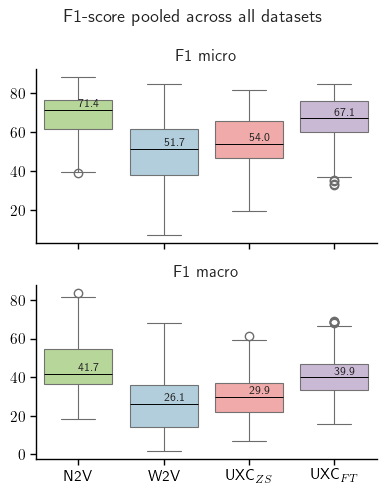

In [14]:
boxplot_group(RQ1, ['f1_micro', 'f1_macro'],
              'F1-score pooled across all datasets',
              fig_path('RQ1_boxplot_f1_pooled.pdf'))

In [15]:
rq1_stats = stat_table(RQ1, ['f1_micro', 'f1_macro'])
save_stats(rq1_stats, 'rq1_stats.csv')
display(rq1_stats[rq1_stats['dataset'] == 'ALL (pooled)'])
print('Holm-significant per-system tests:', int((rq1_stats[rq1_stats.dataset != "ALL (pooled)"].sig_holm == "*").sum()),
      'of', int((rq1_stats.dataset != "ALL (pooled)").sum()))

saved results\Statiscal_Test\rq1_stats.csv  (132 rows)


,metric,comparison,method_a,method_b,dataset,method_a med%,method_b med%,median_diff,median_diff%,method_a IQR,method_b IQR,stat,p,p_holm,sig,sig_holm,Cliff's d,effect
10,f1_micro,N2V vs W2V,N2V,W2V,ALL (pooled),71.4,51.7,0.1970,19.7,0.1497,0.2389,805572.5,0.0000,0.0000,*,*,0.611,large
21,f1_micro,N2V vs UXC$_{ZS}$,N2V,UXC$_{ZS}$,ALL (pooled),71.4,54.0,0.1733,17.3,0.1497,0.1889,792466.0,0.0000,0.0000,*,*,0.585,large
32,f1_micro,N2V vs UXC$_{FT}$,N2V,UXC$_{FT}$,ALL (pooled),71.4,67.1,0.0424,4.2,0.1497,0.1573,563476.5,0.0000,0.0000,*,*,0.127,negligible
43,f1_micro,W2V vs UXC$_{ZS}$,W2V,UXC$_{ZS}$,ALL (pooled),51.7,54.0,-0.0236,-2.4,0.2389,0.1889,413346.5,0.0000,0.0000,*,*,-0.173,small
54,f1_micro,W2V vs UXC$_{FT}$,W2V,UXC$_{FT}$,ALL (pooled),51.7,67.1,-0.1545,-15.5,0.2389,0.1573,235800.5,0.0000,0.0000,*,*,-0.528,large
65,f1_micro,UXC$_{ZS}$ vs UXC$_{FT}$,UXC$_{ZS}$,UXC$_{FT}$,ALL (pooled),54.0,67.1,-0.1309,-13.1,0.1889,0.1573,265261.0,0.0000,0.0000,*,*,-0.469,medium
76,f1_macro,N2V vs W2V,N2V,W2V,ALL (pooled),41.7,26.1,0.1557,15.6,0.1813,0.2158,831041.5,0.0000,0.0000,*,*,0.662,large
87,f1_macro,N2V vs UXC$_{ZS}$,N2V,UXC$_{ZS}$,ALL (pooled),41.7,29.9,0.1182,11.8,0.1813,0.1511,825255.0,0.0000,0.0000,*,*,0.651,large
98,f1_macro,N2V vs UXC$_{FT}$,N2V,UXC$_{FT}$,ALL (pooled),41.7,39.9,0.0178,1.8,0.1813,0.1371,607670.5,0.0000,0.0000,*,*,0.215,small
109,f1_macro,W2V vs UXC$_{ZS}$,W2V,UXC$_{ZS}$,ALL (pooled),26.1,29.9,-0.0375,-3.8,0.2158,0.1511,425337.0,0.0000,0.0000,*,*,-0.149,small


Holm-significant per-system tests: 110 of 120


---
## 4. RQ2 — Graph configurations (MLP / F / FM / FF / FFM)

F = file nodes; FM = files + one aggregate member node per file; FF = folders + files; FFM = folders + files + members.
These are **configuration comparisons**: moving from MLP to a graph also changes the classifier, member-content placement and sometimes the learning schedule. Tests are within one representation.

In [342]:
RQ2_CONDITIONS = ['MLP', 'F', 'FM', 'FF', 'FFM']

def _rep_conditions(prefix, mlp_key=None):
    return {
        'MLP': RQ2[mlp_key if mlp_key else prefix],
        'F':   RQ2[f'{prefix}$_{{F}}$'],
        'FM':  RQ2[f'{prefix}$_{{FM}}$'],
        'FF':  RQ2[f'{prefix}$_{{FF}}$'],
        'FFM': RQ2[f'{prefix}$_{{FFM}}$'],
    }

RQ2_LINEPLOT_DATA = {
    'W2V':        _rep_conditions('W2V'),
    'N2V':        _rep_conditions('N2V'),
    'UXC$_{FT}$': _rep_conditions('UXC', mlp_key='UXC$_{FT}$'),
}

for m in ['f1_macro', 'f1_micro']:
    print(f'=== RQ2 median {m} (%) ===')
    display(summary_table_(RQ2, m).style.apply(bold_max, axis=0).format('{:.1f}'))

=== RQ2 median f1_macro (%) ===


,A.UML,C.Img,JabRef,Lucene,SH-3D,T.Mates,Bash,HDF,Chrome,HDC
method,,,,,,,,,,
W2V,33.9,24.3,42.6,57.9,22.6,30.4,5.8,3.9,14.3,29.8
W2V$_{F}$,29.8,26.2,41.7,51.4,32.2,44.8,14.0,34.8,15.7,26.3
W2V$_{FM}$,32.3,23.6,40.3,54.1,19.9,26.5,19.0,45.5,16.2,33.7
W2V$_{FF}$,65.7,84.0,71.6,81.2,87.7,69.4,61.5,85.3,45.5,49.1
W2V$_{FFM}$,91.1,99.6,79.7,99.6,100.0,99.8,68.1,90.2,55.7,53.2
N2V,53.1,74.1,37.4,64.7,32.7,34.9,39.5,49.3,38.5,39.9
N2V$_{F}$,41.9,65.2,37.1,57.2,31.8,33.6,36.8,46.2,41.2,33.4
N2V$_{FM}$,51.3,74.5,36.1,64.3,30.5,31.3,35.9,47.8,41.3,36.1
N2V$_{FF}$,59.1,87.4,54.4,71.1,77.8,48.2,57.6,76.6,60.3,48.6


=== RQ2 median f1_micro (%) ===


,A.UML,C.Img,JabRef,Lucene,SH-3D,T.Mates,Bash,HDF,Chrome,HDC
method,,,,,,,,,,
W2V,60.2,40.4,80.3,72.6,42.8,58.3,30.7,19.8,52.6,50.4
W2V$_{F}$,58.6,43.9,79.4,68.6,57.2,72.4,32.2,37.7,53.6,44.5
W2V$_{FM}$,61.1,52.2,78.0,71.8,46.7,60.9,36.1,40.2,56.3,55.3
W2V$_{FF}$,86.7,89.2,94.7,94.5,96.3,88.8,77.5,89.4,82.2,83.3
W2V$_{FFM}$,97.5,99.7,95.6,99.6,100.0,99.7,84.5,93.4,86.1,87.3
N2V,73.9,82.5,75.8,79.9,56.3,68.2,63.2,55.3,71.8,71.1
N2V$_{F}$,65.6,74.7,75.5,75.1,63.2,70.6,61.4,51.0,69.7,62.9
N2V$_{FM}$,72.1,82.1,74.6,79.7,54.8,66.3,62.9,54.1,71.1,67.2
N2V$_{FF}$,84.1,91.0,91.9,87.6,92.6,80.9,85.2,85.2,85.9,79.9


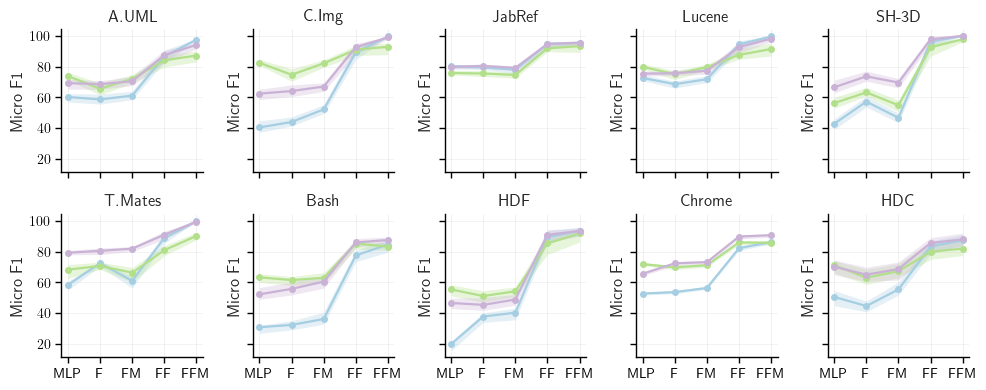

In [346]:
lineplot_(
    RQ2_LINEPLOT_DATA, metric='f1_micro', condition_order=RQ2_CONDITIONS, title='',
    band_alpha=0.3, annotate_median=False, annotate_fontsize=8, annotate_offset=4,
    size=(10,4.2), nrows=2, ncols=5, legends=False,
    save_path=fig_path('RQ2_lineplot_f1_micro.pdf'),
)

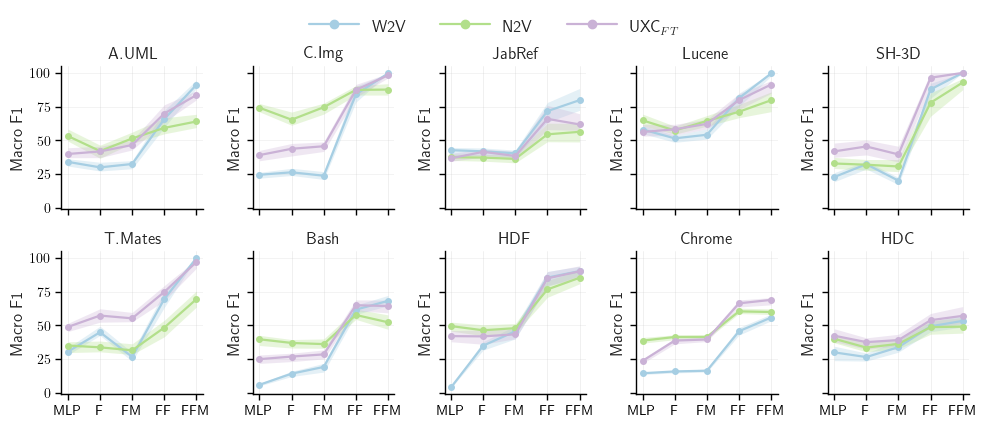

In [349]:
lineplot_(
    RQ2_LINEPLOT_DATA, metric='f1_macro', condition_order=RQ2_CONDITIONS, title='',
    band_alpha=0.3, size=(10, 4.2), nrows=2, ncols=5,
    save_path=fig_path('RQ2_lineplot_f1_macro.pdf'), legends=True,
)

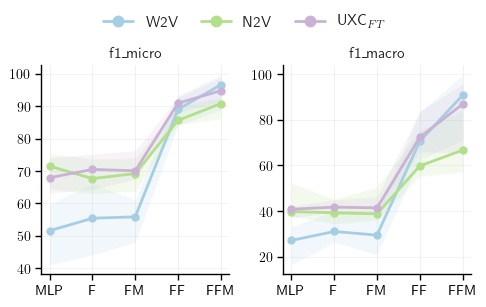

In [345]:
aggregate_lineplot_(
    RQ2_LINEPLOT_DATA, metrics=['f1_micro', 'f1_macro'], condition_order=RQ2_CONDITIONS,
    title='', size=(5, 3), save_path=fig_path('RQ2_aggregate_lineplot_f1.pdf'),
)

In [332]:
def lineplot_macro_micro(data: dict, condition_order: list,
                         size=(18, 6.5), nrows=3, ncols=3,
                         metrics=('f1_macro', 'f1_micro'),
                         metric_names=('Macro F1', 'Micro F1'),
                         save_path=None,
                         show_band=True, band_alpha=0.15,
                         annotate_median: bool = False, annotate_fontsize=8,
                         annotate_offset=4, legends: bool = True):

    found_ds = {
        ds
        for rep_dict in data.values()
        for cond_df in rep_dict.values()
        for ds in cond_df['dataset'].unique()
    }
    all_ds = [ds for ds in DATASET_ORDER if ds in found_ds]

    max_panels = nrows * ncols
    if len(all_ds) > max_panels:
        print(f'Warning: {len(all_ds)} systems found, only plotting the first {max_panels}.')
        all_ds = all_ds[:max_panels]

    labels = list(data.keys())
    colors = method_colors(labels)

    n_reps = len(labels)
    offset_step = annotate_offset if n_reps <= 1 else annotate_offset * 1.2
    rep_offsets = {
        rep: annotate_offset + i * offset_step
        for i, rep in enumerate(labels)
    }

    fig = plt.figure(figsize=size, layout='constrained')
    subfigs = fig.subfigures(1, 2, wspace=0.04)

    first_ax = None

    for sf, metric, metric_name in zip(subfigs, metrics, metric_names):
        axes = sf.subplots(nrows, ncols, sharey=True, sharex=True, squeeze=False)
        axes = axes.flatten(order='C')
        if first_ax is None:
            first_ax = axes[0]

        for ax_i, ds in enumerate(all_ds):
            ax = axes[ax_i]

            for rep in labels:
                xs, meds, q1s, q3s = [], [], [], []
                for cond in condition_order:
                    if cond not in data[rep]:
                        continue
                    df = data[rep][cond]
                    vals = df.loc[df['dataset'] == ds, metric].dropna().values * 100
                    if len(vals) == 0:
                        continue
                    xs.append(cond)
                    meds.append(np.median(vals))
                    q1s.append(np.percentile(vals, 25))
                    q3s.append(np.percentile(vals, 75))

                if not xs:
                    continue

                ax.plot(
                    xs, meds,
                    marker='o', markersize=4, linewidth=1.6,
                    color=colors[rep], label=rep, zorder=3
                )

                if show_band:
                    ax.fill_between(
                        xs, q1s, q3s,
                        color=colors[rep], alpha=band_alpha, linewidth=0, zorder=1
                    )

                if annotate_median:
                    for x, m in zip(xs, meds):
                        ax.annotate(
                            f'{m:.0f}',
                            xy=(x, m),
                            xytext=(0, rep_offsets[rep]),
                            textcoords='offset points',
                            ha='center', va='bottom',
                            fontsize=annotate_fontsize,
                            color=colors[rep],
                            zorder=4,
                        )

            ax.set_title(ds, fontsize=11)
            ax.set_ylabel('')
            ax.set_xlabel('')
            ax.tick_params(axis='x', labelsize=9.5, rotation=30)
            ax.tick_params(axis='y', labelsize=10)
            ax.grid(axis='y', linewidth=0.4, alpha=0.4)

            if annotate_median:
                ymin, ymax = ax.get_ylim()
                ax.set_ylim(ymin, ymax + 0.12 * (ymax - ymin))

        for ax_i in range(len(all_ds), len(axes)):
            axes[ax_i].set_visible(False)

        sf.suptitle(metric_name, fontsize=12)

    if legends and first_ax is not None:
        handles, labs = first_ax.get_legend_handles_labels()
        fig.legend(
            handles, labs,
            loc='outside upper center',
            ncol=len(labels), fontsize=12, frameon=False,
            handlelength=3,
            handleheight=1.5,
            markerscale=1.5,
            columnspacing=2.0,
        )

    if save_path:
        plt.savefig(save_path, bbox_inches='tight', dpi=300)
    plt.show()

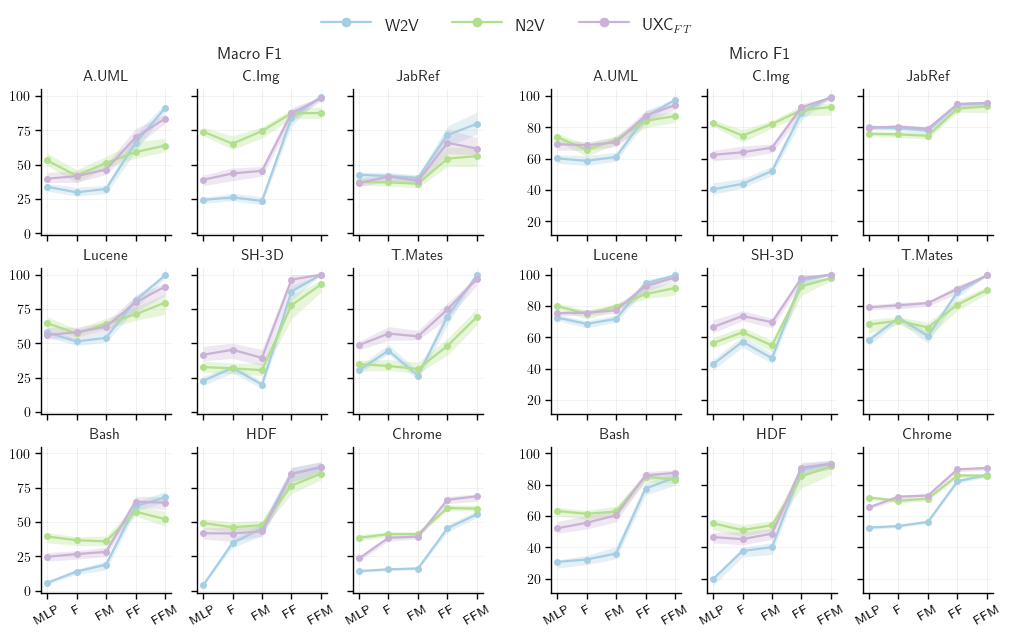

In [333]:
lineplot_macro_micro(
    RQ2_LINEPLOT_DATA, condition_order=RQ2_CONDITIONS,
    band_alpha=0.3, size=(10, 6.3), nrows=3, ncols=3,
    legends=True,
    save_path=fig_path('RQ2_lineplot_f1_macro_micro.pdf'),
)

In [334]:
rq2_pairs = [(a, b) for fam in RQ2_FAMILIES.values() for a, b in combinations(fam, 2)]
rq2_stats = stat_table(RQ2, ['f1_micro', 'f1_macro'], pairs=rq2_pairs)
fam_of = {l: f for f, labs in RQ2_FAMILIES.items() for l in labs}
rq2_stats.insert(1, 'representation', rq2_stats['method_a'].map(fam_of))
save_stats(rq2_stats, 'rq2_stats.csv')
display(rq2_stats[rq2_stats['dataset'] == 'ALL (pooled)'])

saved results\Statiscal_Test\rq2_stats.csv  (660 rows)


,metric,representation,comparison,method_a,method_b,dataset,method_a med%,method_b med%,median_diff,median_diff%,method_a IQR,method_b IQR,stat,p,p_holm,sig,sig_holm,Cliff's d,effect
10,f1_micro,W2V,W2V vs W2V$_{F}$,W2V,W2V$_{F}$,ALL (pooled),51.7,54.2,-0.0253,-2.5,0.2389,0.2582,438277.5,0.0000,0.0001,*,*,-0.123,negligible
21,f1_micro,W2V,W2V vs W2V$_{FM}$,W2V,W2V$_{FM}$,ALL (pooled),51.7,55.7,-0.0407,-4.1,0.2389,0.1853,414395.0,0.0000,0.0000,*,*,-0.171,small
32,f1_micro,W2V,W2V vs W2V$_{FF}$,W2V,W2V$_{FF}$,ALL (pooled),51.7,88.5,-0.3685,-36.8,0.2389,0.1115,22493.5,0.0000,0.0000,*,*,-0.955,large
43,f1_micro,W2V,W2V vs W2V$_{FFM}$,W2V,W2V$_{FFM}$,ALL (pooled),51.7,96.5,-0.4479,-44.8,0.2389,0.1121,5914.5,0.0000,0.0000,*,*,-0.988,large
54,f1_micro,W2V,W2V$_{F}$ vs W2V$_{FM}$,W2V$_{F}$,W2V$_{FM}$,ALL (pooled),54.2,55.7,-0.0154,-1.5,0.2582,0.1853,477312.0,0.0789,1.0000,,,-0.045,negligible
65,f1_micro,W2V,W2V$_{F}$ vs W2V$_{FF}$,W2V$_{F}$,W2V$_{FF}$,ALL (pooled),54.2,88.5,-0.3432,-34.3,0.2582,0.1115,21269.5,0.0000,0.0000,*,*,-0.957,large
76,f1_micro,W2V,W2V$_{F}$ vs W2V$_{FFM}$,W2V$_{F}$,W2V$_{FFM}$,ALL (pooled),54.2,96.5,-0.4226,-42.3,0.2582,0.1121,5312.0,0.0000,0.0000,*,*,-0.989,large
87,f1_micro,W2V,W2V$_{FM}$ vs W2V$_{FF}$,W2V$_{FM}$,W2V$_{FF}$,ALL (pooled),55.7,88.5,-0.3278,-32.8,0.1853,0.1115,15961.5,0.0000,0.0000,*,*,-0.968,large
98,f1_micro,W2V,W2V$_{FM}$ vs W2V$_{FFM}$,W2V$_{FM}$,W2V$_{FFM}$,ALL (pooled),55.7,96.5,-0.4072,-40.7,0.1853,0.1121,3717.0,0.0000,0.0000,*,*,-0.993,large
109,f1_micro,W2V,W2V$_{FF}$ vs W2V$_{FFM}$,W2V$_{FF}$,W2V$_{FFM}$,ALL (pooled),88.5,96.5,-0.0794,-7.9,0.1115,0.1121,246204.5,0.0000,0.0000,*,*,-0.508,large


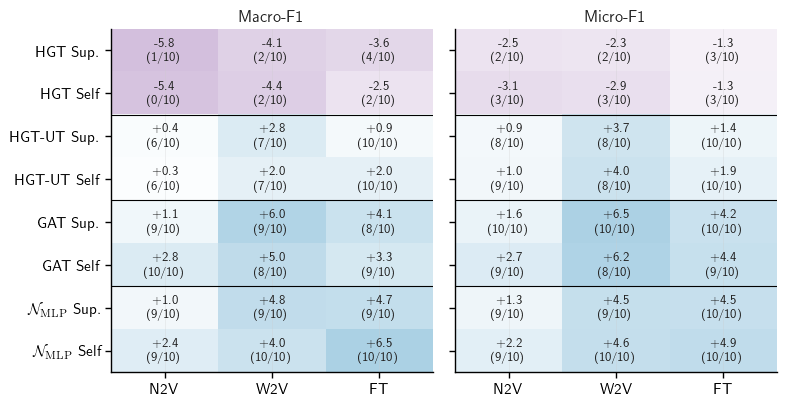

In [25]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

OUT = Path("results/rq3_nine")
d = pd.read_csv(OUT / "rq3_reps.csv").rename(columns={"schedule": "sched"})
REPS = [("N2V", "N2V"), ("W2V", "W2V"), ("UXC_FT", "FT")]   # FT label; use r"\ft" text as you prefer
MODELS = [("HGT", "HGT"), ("uHGT", "HGT-UT"), ("GAT", "GAT"), ("MLP", r"$\mathcal{N}_\mathrm{MLP}$")]
ROWS = [(m, s) for m, _ in MODELS for s in ("sup", "self")]
LABEL = dict(MODELS)
SCHED = {"sup": "Sup.", "self": "Self"}

cmap = LinearSegmentedColormap.from_list("lossgain", ["#CAB2D6", "#ffffff", "#A6CEE3"])
norm = TwoSlopeNorm(vmin=-7, vcenter=0, vmax=7)

fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), sharey=True)
for ax, (metric, title) in zip(axes, [("macro", "Macro-F1"), ("micro", "Micro-F1")]):
    med = np.zeros((len(ROWS), len(REPS)))
    pos = np.zeros_like(med, dtype=int)
    for i, (m, s) in enumerate(ROWS):
        for j, (rep, _) in enumerate(REPS):
            r = d[(d.rep == rep) & (d.model == m) & (d.sched == s) & (d.metric == metric)].iloc[0]
            med[i, j], pos[i, j] = r["median"], int(r["pos"])
    ax.imshow(med, cmap=cmap, norm=norm, aspect="auto")
    for i in range(len(ROWS)):
        for j in range(len(REPS)):
            ax.text(j, i, f"{med[i, j]:+.1f}\n({pos[i, j]}/{int(d.n_sys.max())})", ha="center", va="center", fontsize=9)
    ax.set_xticks(range(len(REPS)), [lab for _, lab in REPS])
    ax.set_title(title)
    for k in range(1, len(MODELS)):                      # separate model groups
        ax.axhline(2 * k - 0.5, color="black", lw=0.8)
ax = axes[0]
ax.set_yticks(range(len(ROWS)), [f"{LABEL[m]}  {SCHED[s]}" for m, s in ROWS])
fig.tight_layout()
fig.savefig(OUT / "rq3_heatmap.pdf", bbox_inches="tight")
plt.show()

---
## 5. RQ2 — Homophily x connectivity quadrants

System properties come from the supervisor's frozen graph table (`results/graph_properties.csv`):
homophily = unique directed homophily, connectivity = mean undirected degree, module size = files / modules.
Old thresholds: homophily 0.50, module size 20. The old connectivity cut (13) would leave one high-degree homophilic system under the new degree convention, so the cut is **10** (change `CONNECTIVITY_THRESHOLD` below).

In [26]:
gp = pd.read_csv(GRAPH_PROPS)
gp['system'] = gp['system'].replace(SYS_RENAME)
SYSTEM_PROPERTIES = {
    r.system: {
        'homophily': round(float(r.unique_directed_homophily), 2),
        'avg_degree': round(float(r.mean_undirected_degree), 1),
        'module_size': round(float(r.files) / float(r.modules), 2),
    }
    for r in gp.itertuples()
}
pd.DataFrame(SYSTEM_PROPERTIES).T.loc[DATASET_ORDER]

,homophily,avg_degree,module_size
A.UML,0.55,9.6,54.71
C.Img,0.61,9.3,15.67
JabRef,0.56,10.8,168.83
Lucene,0.68,11.9,150.57
SH-3D,0.36,14.3,18.56
T.Mates,0.34,17.1,51.87
Bash,0.58,6.9,20.86
HDF,0.35,7.0,17.00
Chrome,0.58,15.9,265.84
HDC,0.63,5.2,18.82


In [27]:
# -------------------------------------------------------------------
# Validate the ten datasets and derive graph-property groups.
#
# Homophilic: H >= 0.50
# Heterophilic: H < 0.50
# Low connectivity: Avg. degree < 10
# High connectivity: Avg. degree >= 10
# Small modules: Module size < 20
# Large modules: Module size >= 20
# -------------------------------------------------------------------
METRIC_LABELS = ["Metric1", "Metric2", "Metric3"]
DATASETS = ['A.UML',
            'C.Img',
            'JabRef',
            'Lucene',
            'SH-3D',
            'T.Mates',
            'Bash',
            'HDF',
            'Chrome',
            'HDC']
HOMOPHILY_THRESHOLD = 0.50
CONNECTIVITY_THRESHOLD = 10.0
MODULE_SIZE_THRESHOLD = 20.0

missing_datasets = sorted(set(DATASETS) - set(SYSTEM_PROPERTIES))

if missing_datasets:
    raise ValueError(
        'Missing graph properties for dataset labels: '
        f'{missing_datasets}'
    )

rq3_properties = {
    dataset: SYSTEM_PROPERTIES[dataset]
    for dataset in DATASETS
}

homophily_values = np.array(
    [values['homophily'] for values in rq3_properties.values()],
    dtype=float,
)

avg_degree_values = np.array(
    [values['avg_degree'] for values in rq3_properties.values()],
    dtype=float,
)

module_size_values = np.array(
    [values['module_size'] for values in rq3_properties.values()],
    dtype=float,
)

if np.isnan(homophily_values).any():
    raise ValueError('At least one RQ3 system has missing homophily.')

if np.isnan(avg_degree_values).any():
    raise ValueError('At least one RQ3 system has missing average degree.')

if np.isnan(module_size_values).any():
    raise ValueError('At least one RQ3 system has missing module size.')

homophilic_systems = sorted(
    dataset
    for dataset, values in rq3_properties.items()
    if values['homophily'] >= HOMOPHILY_THRESHOLD
)

heterophilic_systems = sorted(
    dataset
    for dataset, values in rq3_properties.items()
    if values['homophily'] < HOMOPHILY_THRESHOLD
)

low_connectivity_systems = sorted(
    dataset
    for dataset, values in rq3_properties.items()
    if values['avg_degree'] < CONNECTIVITY_THRESHOLD
)

high_connectivity_systems = sorted(
    dataset
    for dataset, values in rq3_properties.items()
    if values['avg_degree'] >= CONNECTIVITY_THRESHOLD
)

small_module_systems = sorted(
    dataset
    for dataset, values in rq3_properties.items()
    if values['module_size'] < MODULE_SIZE_THRESHOLD
)

large_module_systems = sorted(
    dataset
    for dataset, values in rq3_properties.items()
    if values['module_size'] >= MODULE_SIZE_THRESHOLD
)

for representation, condition_data in RQ2_LINEPLOT_DATA.items():
    for condition, df in condition_data.items():
        RQ2_LINEPLOT_DATA[representation][condition] = df[
            df['dataset'].isin(DATASETS)
        ].copy()

print('=' * 72)
print('Graph-property thresholds and system groups')
print('=' * 72)

print(f'\nHomophily threshold: H = {HOMOPHILY_THRESHOLD:.2f}')
print(f'Homophilic systems (H >= {HOMOPHILY_THRESHOLD:.2f}; n={len(homophilic_systems)}):')
print(homophilic_systems)
print(f'Heterophilic systems (H < {HOMOPHILY_THRESHOLD:.2f}; n={len(heterophilic_systems)}):')
print(heterophilic_systems)

print(f'\nConnectivity threshold: Avg. degree = {CONNECTIVITY_THRESHOLD:.2f}')
print(f'Low-connectivity systems (Avg. degree < {CONNECTIVITY_THRESHOLD:.2f}; n={len(low_connectivity_systems)}):')
print(low_connectivity_systems)
print(f'High-connectivity systems (Avg. degree >= {CONNECTIVITY_THRESHOLD:.2f}; n={len(high_connectivity_systems)}):')
print(high_connectivity_systems)

print(f'\nModule-size threshold: Module size = {MODULE_SIZE_THRESHOLD:.2f}')
print(f'Small-module systems (Module size < {MODULE_SIZE_THRESHOLD:.2f}; n={len(small_module_systems)}):')
print(small_module_systems)
print(f'Large-module systems (Module size >= {MODULE_SIZE_THRESHOLD:.2f}; n={len(large_module_systems)}):')
print(large_module_systems)

property_summary_df = (
    pd.DataFrame.from_dict(rq3_properties, orient='index')
    .rename_axis('dataset')
    .reset_index()
)

property_summary_df['homophily_group'] = np.where(
    property_summary_df['homophily'] >= HOMOPHILY_THRESHOLD,
    'Homophilic',
    'Heterophilic',
)

property_summary_df['connectivity_group'] = np.where(
    property_summary_df['avg_degree'] >= CONNECTIVITY_THRESHOLD,
    'High connectivity',
    'Low connectivity',
)

property_summary_df['module_size_group'] = np.where(
    property_summary_df['module_size'] >= MODULE_SIZE_THRESHOLD,
    'Large modules',
    'Small modules',
)

display(
    property_summary_df[
        [
            'dataset',
            'homophily',
            'homophily_group',
            'avg_degree',
            'connectivity_group',
            'module_size',
            'module_size_group',
        ]
    ]
)

Graph-property thresholds and system groups

Homophily threshold: H = 0.50
Homophilic systems (H >= 0.50; n=7):
['A.UML', 'Bash', 'C.Img', 'Chrome', 'HDC', 'JabRef', 'Lucene']
Heterophilic systems (H < 0.50; n=3):
['HDF', 'SH-3D', 'T.Mates']

Connectivity threshold: Avg. degree = 10.00
Low-connectivity systems (Avg. degree < 10.00; n=5):
['A.UML', 'Bash', 'C.Img', 'HDC', 'HDF']
High-connectivity systems (Avg. degree >= 10.00; n=5):
['Chrome', 'JabRef', 'Lucene', 'SH-3D', 'T.Mates']

Module-size threshold: Module size = 20.00
Small-module systems (Module size < 20.00; n=4):
['C.Img', 'HDC', 'HDF', 'SH-3D']
Large-module systems (Module size >= 20.00; n=6):
['A.UML', 'Bash', 'Chrome', 'JabRef', 'Lucene', 'T.Mates']


,dataset,homophily,homophily_group,avg_degree,connectivity_group,module_size,module_size_group
0,A.UML,0.55,Homophilic,9.6,Low connectivity,54.71,Large modules
1,C.Img,0.61,Homophilic,9.3,Low connectivity,15.67,Small modules
2,JabRef,0.56,Homophilic,10.8,High connectivity,168.83,Large modules
3,Lucene,0.68,Homophilic,11.9,High connectivity,150.57,Large modules
4,SH-3D,0.36,Heterophilic,14.3,High connectivity,18.56,Small modules
5,T.Mates,0.34,Heterophilic,17.1,High connectivity,51.87,Large modules
6,Bash,0.58,Homophilic,6.9,Low connectivity,20.86,Large modules
7,HDF,0.35,Heterophilic,7.0,Low connectivity,17.00,Small modules
8,Chrome,0.58,Homophilic,15.9,High connectivity,265.84,Large modules
9,HDC,0.63,Homophilic,5.2,Low connectivity,18.82,Small modules


In [28]:
for representation, condition_data in RQ2_LINEPLOT_DATA.items():
    for condition, df in condition_data.items():
        df = df[df['dataset'].isin(DATASETS)].copy()

        df['homophily_type'] = df['dataset'].map(
            lambda dataset: (
                'Homophilic'
                if SYSTEM_PROPERTIES[dataset]['homophily'] >= HOMOPHILY_THRESHOLD
                else 'Heterophilic'
            )
        )

        df['connectivity_type'] = df['dataset'].map(
            lambda dataset: (
                'High connectivity'
                if SYSTEM_PROPERTIES[dataset]['avg_degree'] >= CONNECTIVITY_THRESHOLD
                else 'Low connectivity'
            )
        )

        df['module_size_type'] = df['dataset'].map(
            lambda dataset: (
                'Large modules'
                if SYSTEM_PROPERTIES[dataset]['module_size'] >= MODULE_SIZE_THRESHOLD
                else 'Small modules'
            )
        )

        RQ2_LINEPLOT_DATA[representation][condition] = df

input_systems = sorted(
    {
        dataset
        for condition_data in RQ2_LINEPLOT_DATA.values()
        for df in condition_data.values()
        for dataset in df['dataset'].dropna().unique()
    }
)

print('All systems present in RQ2_LINEPLOT_DATA:')
print(input_systems)
print(f'n = {len(input_systems)}')
avg_degree_values = [
    SYSTEM_PROPERTIES[dataset]['avg_degree']
    for dataset in input_systems
]
module_size_values = [
    SYSTEM_PROPERTIES[dataset]['module_size']
    for dataset in input_systems
]
print(float(np.median(avg_degree_values)))
print(float(np.median(module_size_values)))

All systems present in RQ2_LINEPLOT_DATA:
['A.UML', 'Bash', 'C.Img', 'Chrome', 'HDC', 'HDF', 'JabRef', 'Lucene', 'SH-3D', 'T.Mates']
n = 10
10.2
36.364999999999995


In [29]:
def aggregate_quadrant_subplots(
    data,
    metrics,
    condition_order,
    group_column,
    groups,
    size=(5, 5.5),
    save_path=None,
    show_band=True,
    band_alpha=0.25,
    metric_labels=None,
):
    if len(groups) != 4:
        raise ValueError(
            '`groups` must contain exactly four quadrant labels '
            'in the order: low-k/low-H, high-k/low-H, '
            'low-k/high-H, high-k/high-H.'
        )

    if len(metrics) != 1:
        raise ValueError(
            'A 2×2 quadrant matrix supports exactly one metric per call. '
            'Call this function separately for each metric.'
        )

    if metric_labels is None:
        metric_labels = {}

    metric = metrics[0]
    labels = list(data.keys())
    colors = method_colors(labels)

    group_has_data = {}

    for group in groups:
        has_data = False

        for rep in labels:
            for condition in condition_order:
                if condition not in data[rep]:
                    continue

                df = data[rep][condition]

                if group_column not in df.columns:
                    raise KeyError(
                        f"Column '{group_column}' is missing from "
                        f"data['{rep}']['{condition}']."
                    )

                group_values = df.loc[
                    df[group_column].eq(group),
                    metric,
                ].dropna()

                if not group_values.empty:
                    has_data = True
                    break

            if has_data:
                break

        group_has_data[group] = has_data

    if not any(group_has_data.values()):
        raise ValueError(
            'None of the requested homophily × connectivity quadrants '
            f'contains data for metric "{metric}".'
        )

    fig, axes = plt.subplots(
        nrows=2,
        ncols=2,
        figsize=size,
        sharex=True,
        sharey=True,
        squeeze=False,
    )

    metric_label = metric_labels.get(
        metric,
        metric.replace('_', ' ').title(),
    )

    all_handles = []
    all_legend_labels = []

    for group_index, group in enumerate(groups):
        ax = axes.flat[group_index]
        panel_systems = set()

        if not group_has_data[group]:
            ax.set_visible(False)
            continue

        for rep in labels:
            xs = []
            meds = []
            q1s = []
            q3s = []

            for condition in condition_order:
                if condition not in data[rep]:
                    continue

                df = data[rep][condition]

                df_group = df.loc[
                    df[group_column].eq(group)
                ].copy()

                if df_group.empty:
                    continue

                per_system_medians = []
                all_run_values = []

                for dataset in df_group['dataset'].dropna().unique():
                    values = df_group.loc[
                        df_group['dataset'].eq(dataset),
                        metric,
                    ].dropna()

                    if values.empty:
                        continue

                    panel_systems.add(dataset)

                    values_np = values.to_numpy(dtype=float) * 100
                    per_system_medians.append(np.median(values_np))
                    all_run_values.extend(values_np.tolist())

                if not per_system_medians:
                    continue

                per_system_medians = np.asarray(
                    per_system_medians,
                    dtype=float,
                )
                all_run_values = np.asarray(
                    all_run_values,
                    dtype=float,
                )

                xs.append(condition)
                meds.append(np.median(per_system_medians))
                q1s.append(np.percentile(all_run_values, 25))
                q3s.append(np.percentile(all_run_values, 75))

            if not xs:
                continue

            line, = ax.plot(
                xs,
                meds,
                marker='o',
                markersize=5,
                linewidth=2,
                color=colors[rep],
                label=rep,
                zorder=3,
            )

            if rep not in all_legend_labels:
                all_handles.append(line)
                all_legend_labels.append(rep)

            if show_band:
                ax.fill_between(
                    xs,
                    q1s,
                    q3s,
                    color=colors[rep],
                    alpha=band_alpha,
                    linewidth=0,
                    zorder=1,
                )

        ax.set_title(
            f'{group}\n$n={len(panel_systems)}$',
            fontsize=11,
            pad=7,
        )

        ax.grid(axis='y', linewidth=0.4, alpha=0.4)
        ax.tick_params(axis='x', labelsize=10)
        ax.tick_params(axis='y', labelsize=10)

    axes[0, 0].set_ylabel(metric_label, fontsize=12)
    axes[1, 0].set_ylabel(metric_label, fontsize=12)

    axes[1, 0].set_xlabel('')
    axes[1, 1].set_xlabel('')

    fig.text(
        0.50,
        -0.02,
        r'Connectivity: low $\langle k \rangle$ $\longrightarrow$ '
        r'high $\langle k \rangle$',
        ha='center',
        va='center',
        fontsize=12,
    )

    fig.text(
        -0.02,
        0.50,
        r'Homophily: low $\mathcal{H}$ $\longrightarrow$ '
        r'high $\mathcal{H}$',
        ha='center',
        va='center',
        rotation='vertical',
        fontsize=12,
    )

    if all_handles:
        fig.legend(
            all_handles,
            all_legend_labels,
            loc='upper center',
            bbox_to_anchor=(0.5, 1.05),
            ncol=len(all_legend_labels),
            fontsize=12.5,
            frameon=False,
            markerscale=1.2,
            columnspacing=1.2,
        )

    fig.tight_layout()

    if save_path is not None:
        fig.savefig(
            save_path,
            bbox_inches='tight',
        )

    plt.show()

    return fig, axes

In [30]:
def quantile_thresholds(property_name: str, datasets: list, n_groups: int) -> list:
    """
    Return the `n_groups - 1` quantile cut points for
    `SYSTEM_PROPERTIES[d][property_name]` across `datasets`, so a property can
    be split into `n_groups` roughly-equal-sized bins without hand-picking
    thresholds. Pass explicit thresholds to `tag_property_group` instead of
    calling this when an exact, meaningful cut point is wanted (e.g. the
    homophily=0.5 / avg_degree=13 boundaries used elsewhere in this notebook).
    """
    values = sorted(SYSTEM_PROPERTIES[d][property_name] for d in datasets)
    qs = [i / n_groups for i in range(1, n_groups)]
    return [float(np.quantile(values, q)) for q in qs]

In [31]:
def tag_property_group(
    data: dict,
    datasets: list,
    column_name: str,
    property_name: str,
    thresholds: list,
    labels: list,
) -> None:
    """
    Tag every (representation, condition) dataframe in `data` with a new
    `column_name`, computed by binning `SYSTEM_PROPERTIES[dataset][property_name]`
    against `thresholds` (ascending) into `labels` (low -> high; must satisfy
    len(labels) == len(thresholds) + 1). Rows are first restricted to `datasets`.

    Generic replacement for the repeated inline
    `for representation... for condition... df[...] = np.where(...)` tagging
    loops used above for homophily / connectivity / module-size -- works for
    any property in SYSTEM_PROPERTIES and any number of levels, not just two
    or four. Mutates `data` in place, same as the existing tagging blocks.
    """
    if len(labels) != len(thresholds) + 1:
        raise ValueError(
            f'len(labels) ({len(labels)}) must equal len(thresholds) + 1 '
            f'({len(thresholds) + 1}).'
        )

    def classify(dataset):
        value = SYSTEM_PROPERTIES[dataset][property_name]
        for threshold, label in zip(thresholds, labels[:-1]):
            if value < threshold:
                return label
        return labels[-1]

    for representation, condition_data in data.items():
        for condition, df in condition_data.items():
            df = df[df['dataset'].isin(datasets)].copy()
            df[column_name] = df['dataset'].map(classify)
            data[representation][condition] = df

In [32]:
def aggregate_group_subplots(
    data: dict,
    metrics: list,
    condition_order: list,
    group_column: str,
    groups: list,
    ncols: int = None,
    size: tuple = None,
    save_path=None,
    show_band: bool = True,
    band_alpha: float = 0.2,
    metric_labels: dict = None,
):

    if metric_labels is None:
        metric_labels = {}

    n_groups = len(groups)
    ncols = ncols or n_groups
    nrows_per_metric = int(np.ceil(n_groups / ncols))
    total_rows = len(metrics) * nrows_per_metric

    labels_list = list(data.keys())
    colors = method_colors(labels_list)

    if size is None:
        size = (2.6 * ncols, 3.2 * total_rows)

    fig, axes = plt.subplots(
        nrows=total_rows,
        ncols=ncols,
        figsize=size,
        sharex=True,
        sharey=False,
        squeeze=False,
    )

    all_handles, all_legend_labels = [], []

    for metric_index, metric in enumerate(metrics):
        metric_label = metric_labels.get(
            metric,
            metric.replace('_', ' ').title(),
        )

        for group_index, group in enumerate(groups):
            row = metric_index * nrows_per_metric + group_index // ncols
            col = group_index % ncols
            ax = axes[row, col]
            panel_systems = set()

            for rep in labels_list:
                xs, meds, q1s, q3s = [], [], [], []

                for condition in condition_order:
                    if condition not in data[rep]:
                        continue

                    df = data[rep][condition]

                    if group_column not in df.columns:
                        raise KeyError(
                            f"Column '{group_column}' is missing from "
                            f"data['{rep}']['{condition}']."
                        )

                    df_group = df.loc[df[group_column].eq(group)]

                    if df_group.empty:
                        continue

                    per_system_medians = []
                    all_run_values = []

                    for dataset in df_group['dataset'].dropna().unique():
                        values = df_group.loc[
                            df_group['dataset'].eq(dataset),
                            metric,
                        ].dropna()

                        if values.empty:
                            continue

                        panel_systems.add(dataset)
                        values_np = values.to_numpy(dtype=float) * 100
                        per_system_medians.append(np.median(values_np))
                        all_run_values.extend(values_np.tolist())

                    if not per_system_medians:
                        continue

                    xs.append(condition)
                    meds.append(np.median(per_system_medians))
                    q1s.append(np.percentile(all_run_values, 25))
                    q3s.append(np.percentile(all_run_values, 75))

                if not xs:
                    continue

                line, = ax.plot(
                    xs,
                    meds,
                    marker='o',
                    markersize=5,
                    linewidth=2,
                    color=colors[rep],
                    label=rep,
                    zorder=3,
                )

                if rep not in all_legend_labels:
                    all_handles.append(line)
                    all_legend_labels.append(rep)

                if show_band:
                    ax.fill_between(
                        xs,
                        q1s,
                        q3s,
                        color=colors[rep],
                        alpha=band_alpha,
                        linewidth=0,
                        zorder=1,
                    )

            if metric_index == 0:
                ax.set_title(
                    f'{group}\n$n={len(panel_systems)}$',
                    fontsize=11,
                    pad=7,
                )

            if col == 0:
                ax.set_ylabel(metric_label, fontsize=12)

            ax.grid(axis='y', linewidth=0.4, alpha=0.4)
            ax.tick_params(axis='x', labelsize=10)
            ax.tick_params(axis='y', labelsize=10)

    if all_handles:
        fig.legend(
            all_handles,
            all_legend_labels,
            loc='upper center',
            bbox_to_anchor=(0.5, 1.05 if total_rows == 1 else 1.02),
            ncol=len(all_legend_labels),
            fontsize=12.5,
            frameon=False,
            markerscale=1.2,
            columnspacing=1.2,
        )

    fig.tight_layout()

    if save_path is not None:
        fig.savefig(save_path, bbox_inches='tight')

    plt.show()

    return fig, axes

In [33]:
def aggregate_dual_group_subplots(
    data: dict,
    metrics: list,
    condition_order: list,
    row_column: str,
    row_groups: list,
    col_column: str,
    col_groups: list,
    size: tuple = None,
    save_path=None,
    show_band: bool = True,
    band_alpha: float = 0.2,
    metric_labels: dict = None,
    row_axis_label: str = None,
    col_axis_label: str = None,
    share_y: bool = False,
):
    if metric_labels is None:
        metric_labels = {}

    n_rows_groups = len(row_groups)
    n_cols_groups = len(col_groups)
    total_rows = len(metrics) * n_rows_groups

    labels_list = list(data.keys())
    colors = method_colors(labels_list)

    if size is None:
        size = (2.6 * n_cols_groups, 3.0 * total_rows)

    fig, axes = plt.subplots(
        nrows=total_rows,
        ncols=n_cols_groups,
        figsize=size,
        sharex=True,
        sharey=share_y,
        squeeze=False,
    )

    all_handles, all_legend_labels = [], []

    for metric_index, metric in enumerate(metrics):
        metric_label = metric_labels.get(
            metric,
            metric.replace('_', ' ').title(),
        )

        for row_index, row_group in enumerate(row_groups):
            row = metric_index * n_rows_groups + row_index

            for col_index, col_group in enumerate(col_groups):
                ax = axes[row, col_index]
                panel_systems = set()

                for rep in labels_list:
                    xs, meds, q1s, q3s = [], [], [], []

                    for condition in condition_order:
                        if condition not in data[rep]:
                            continue

                        df = data[rep][condition]

                        for needed_col in (row_column, col_column):
                            if needed_col not in df.columns:
                                raise KeyError(
                                    f"Column '{needed_col}' is missing from "
                                    f"data['{rep}']['{condition}']."
                                )

                        df_cell = df.loc[
                            df[row_column].eq(row_group)
                            & df[col_column].eq(col_group)
                        ]

                        if df_cell.empty:
                            continue

                        per_system_medians = []
                        all_run_values = []

                        for dataset in df_cell['dataset'].dropna().unique():
                            values = df_cell.loc[
                                df_cell['dataset'].eq(dataset),
                                metric,
                            ].dropna()

                            if values.empty:
                                continue

                            panel_systems.add(dataset)
                            values_np = values.to_numpy(dtype=float) * 100
                            per_system_medians.append(np.median(values_np))
                            all_run_values.extend(values_np.tolist())

                        if not per_system_medians:
                            continue

                        xs.append(condition)
                        meds.append(np.median(per_system_medians))
                        q1s.append(np.percentile(all_run_values, 25))
                        q3s.append(np.percentile(all_run_values, 75))

                    if not xs:
                        continue

                    line, = ax.plot(
                        xs,
                        meds,
                        marker='o',
                        markersize=5,
                        linewidth=2,
                        color=colors[rep],
                        label=rep,
                        zorder=3,
                    )

                    if rep not in all_legend_labels:
                        all_handles.append(line)
                        all_legend_labels.append(rep)

                    if show_band:
                        ax.fill_between(
                            xs,
                            q1s,
                            q3s,
                            color=colors[rep],
                            alpha=band_alpha,
                            linewidth=0,
                            zorder=1,
                        )

                if not panel_systems:
                    ax.set_visible(False)
                    continue

                ax.set_title(
                    f'{col_group} + {row_group}\n$n={len(panel_systems)}$',
                    fontsize=11,
                    pad=7,
                )

                if col_index == 0:
                    ax.set_ylabel(metric_label, fontsize=11)

                ax.grid(axis='y', linewidth=0.4, alpha=0.4)
                ax.tick_params(axis='x', labelsize=10)
                ax.tick_params(axis='y', labelsize=10)

    if col_axis_label:
        fig.text(0.5, 1.06, col_axis_label, ha='center', va='center', fontsize=12)

    if row_axis_label:
        fig.text(-0.03, 0.5, row_axis_label, ha='center', va='center',
                  rotation='vertical', fontsize=12)

    if all_handles:
        fig.legend(
            all_handles,
            all_legend_labels,
            loc='upper center',
            bbox_to_anchor=(0.5, 1.12 if col_axis_label else 1.05),
            ncol=len(all_legend_labels),
            fontsize=12.5,
            frameon=False,
            markerscale=1.2,
            columnspacing=1.2,
        )

    fig.tight_layout()

    if save_path is not None:
        fig.savefig(save_path, bbox_inches='tight')

    plt.show()

    return fig, axes

### Four quadrants: homophily x connectivity

Low $\langle k \rangle$ + low $\mathcal{H}$ (n=1): ['HDF']
High $\langle k \rangle$ + low $\mathcal{H}$ (n=2): ['SH-3D', 'T.Mates']
Low $\langle k \rangle$ + high $\mathcal{H}$ (n=4): ['A.UML', 'Bash', 'C.Img', 'HDC']
High $\langle k \rangle$ + high $\mathcal{H}$ (n=3): ['Chrome', 'JabRef', 'Lucene']


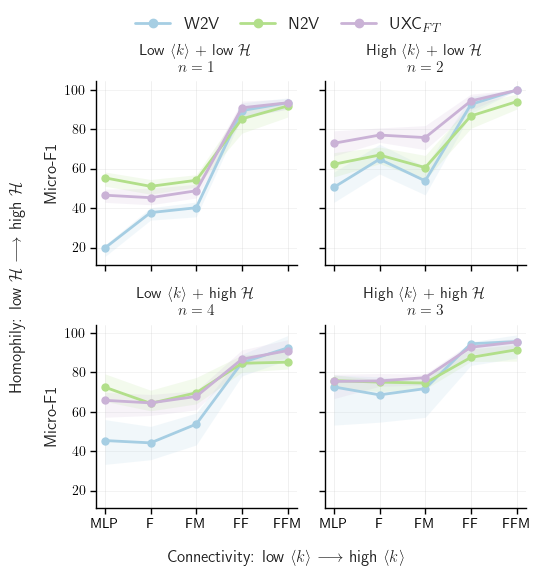

(<Figure size 520x520 with 4 Axes>,
 array([[<Axes: title={'center': 'Low $\\langle k \\rangle$ + low $\\mathcal{H}$\n$n=1$'}, ylabel='Micro-F1'>,
         <Axes: title={'center': 'High $\\langle k \\rangle$ + low $\\mathcal{H}$\n$n=2$'}>],
        [<Axes: title={'center': 'Low $\\langle k \\rangle$ + high $\\mathcal{H}$\n$n=4$'}, ylabel='Micro-F1'>,
         <Axes: title={'center': 'High $\\langle k \\rangle$ + high $\\mathcal{H}$\n$n=3$'}>]],
       dtype=object))

In [34]:
for representation, condition_data in RQ2_LINEPLOT_DATA.items():
    for condition, df in condition_data.items():
        df = df[df['dataset'].isin(DATASETS)].copy()

        df['homophily_type'] = np.where(
            df['dataset'].map(
                lambda dataset: SYSTEM_PROPERTIES[dataset]['homophily']
            ) >= 0.5,
            'Homophilic',
            'Heterophilic',
        )

        df['connectivity_type'] = np.where(
            df['dataset'].map(
                lambda dataset: SYSTEM_PROPERTIES[dataset]['avg_degree']
            ) >= CONNECTIVITY_THRESHOLD,
            'High connectivity',
            'Low connectivity',
        )

        df['homophily_connectivity_type'] = np.select(
            [
                (df['homophily_type'] == 'Heterophilic')
                & (df['connectivity_type'] == 'Low connectivity'),
                (df['homophily_type'] == 'Heterophilic')
                & (df['connectivity_type'] == 'High connectivity'),
                (df['homophily_type'] == 'Homophilic')
                & (df['connectivity_type'] == 'Low connectivity'),
                (df['homophily_type'] == 'Homophilic')
                & (df['connectivity_type'] == 'High connectivity'),
            ],
            [
                r'Low $\langle k \rangle$ + low $\mathcal{H}$',
                r'High $\langle k \rangle$ + low $\mathcal{H}$',
                r'Low $\langle k \rangle$ + high $\mathcal{H}$',
                r'High $\langle k \rangle$ + high $\mathcal{H}$',
            ],
            default="",
        )

        RQ2_LINEPLOT_DATA[representation][condition] = df
quadrant_groups =[
    r'Low $\langle k \rangle$ + low $\mathcal{H}$',
    r'High $\langle k \rangle$ + low $\mathcal{H}$',
    r'Low $\langle k \rangle$ + high $\mathcal{H}$',
    r'High $\langle k \rangle$ + high $\mathcal{H}$',
]

quadrant_systems = {}

for group in quadrant_groups:
    systems = sorted(
        dataset
        for dataset in DATASETS
        if (
            (
                SYSTEM_PROPERTIES[dataset]['avg_degree']
                < CONNECTIVITY_THRESHOLD
                and SYSTEM_PROPERTIES[dataset]['homophily']
                < HOMOPHILY_THRESHOLD
                and group == r'Low $\langle k \rangle$ + low $\mathcal{H}$'
            )
            or (
                SYSTEM_PROPERTIES[dataset]['avg_degree']
                >= CONNECTIVITY_THRESHOLD
                and SYSTEM_PROPERTIES[dataset]['homophily']
                < HOMOPHILY_THRESHOLD
                and group == r'High $\langle k \rangle$ + low $\mathcal{H}$'
            )
            or (
                SYSTEM_PROPERTIES[dataset]['avg_degree']
                < CONNECTIVITY_THRESHOLD
                and SYSTEM_PROPERTIES[dataset]['homophily']
                >= HOMOPHILY_THRESHOLD
                and group == r'Low $\langle k \rangle$ + high $\mathcal{H}$'
            )
            or (
                SYSTEM_PROPERTIES[dataset]['avg_degree']
                >= CONNECTIVITY_THRESHOLD
                and SYSTEM_PROPERTIES[dataset]['homophily']
                >= HOMOPHILY_THRESHOLD
                and group == r'High $\langle k \rangle$ + high $\mathcal{H}$'
            )
        )
    )

    quadrant_systems[group] = systems

for group, systems in quadrant_systems.items():
    print(f'{group} (n={len(systems)}): {systems}')

METRIC_LABELS = {
    'f1_micro': 'Micro-F1',
    'f1_macro': 'Macro-F1',
}

aggregate_quadrant_subplots(
    data=RQ2_LINEPLOT_DATA,
    metrics=['f1_micro'],
    condition_order=RQ2_CONDITIONS,
    group_column='homophily_connectivity_type',
    groups=quadrant_groups,
    band_alpha=0.15,
    size=(5.2,5.2),
    save_path=fig_path('RQ2_homophily_connectivity_quadrants.pdf'),
    metric_labels=METRIC_LABELS,
)

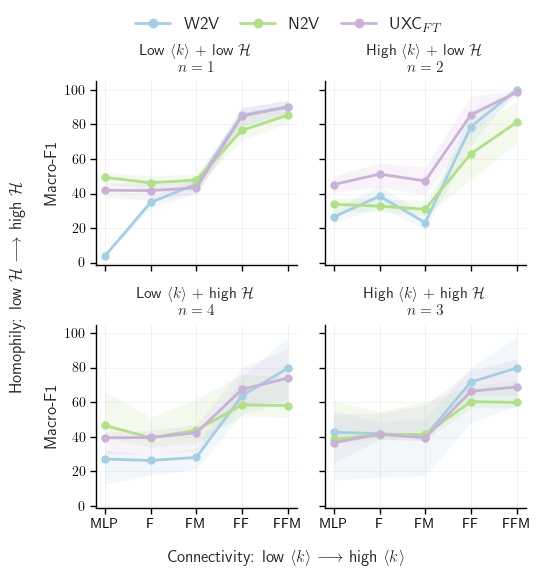

(<Figure size 520x520 with 4 Axes>,
 array([[<Axes: title={'center': 'Low $\\langle k \\rangle$ + low $\\mathcal{H}$\n$n=1$'}, ylabel='Macro-F1'>,
         <Axes: title={'center': 'High $\\langle k \\rangle$ + low $\\mathcal{H}$\n$n=2$'}>],
        [<Axes: title={'center': 'Low $\\langle k \\rangle$ + high $\\mathcal{H}$\n$n=4$'}, ylabel='Macro-F1'>,
         <Axes: title={'center': 'High $\\langle k \\rangle$ + high $\\mathcal{H}$\n$n=3$'}>]],
       dtype=object))

In [35]:
aggregate_quadrant_subplots(
    data=RQ2_LINEPLOT_DATA,
    metrics=['f1_macro'],
    condition_order=RQ2_CONDITIONS,
    group_column='homophily_connectivity_type',
    groups=quadrant_groups,
    band_alpha=0.15,
    size=(5.2, 5.2),
    save_path=fig_path('RQ2_homophily_connectivity_quadrants_f1_macro.pdf'),
    metric_labels=METRIC_LABELS,
)

### Connectivity in three levels, and homophily x connectivity grids

Low $\langle k \rangle$ (n=5): ['A.UML', 'Bash', 'C.Img', 'HDC', 'HDF']
Mid $\langle k \rangle$ (n=3): ['JabRef', 'Lucene', 'SH-3D']
High $\langle k \rangle$ (n=2): ['Chrome', 'T.Mates']


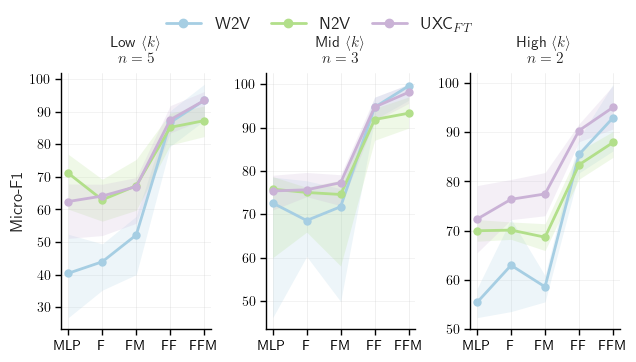

(<Figure size 650x350 with 3 Axes>,
 array([[<Axes: title={'center': 'Low $\\langle k \\rangle$\n$n=5$'}, ylabel='Micro-F1'>,
         <Axes: title={'center': 'Mid $\\langle k \\rangle$\n$n=3$'}>,
         <Axes: title={'center': 'High $\\langle k \\rangle$\n$n=2$'}>]],
       dtype=object))

In [36]:
# avg_degree split into 3 levels. Cuts at 10 and 15 on the frozen mean undirected degree:
# low {HDC, Bash, HDF, C.Img, A.UML}, mid {JabRef, Lucene, SH-3D}, high {Chrome, T.Mates}.
avg_degree_thresholds = [10.0, 15.0]
avg_degree_labels = [r'Low $\langle k \rangle$', r'Mid $\langle k \rangle$', r'High $\langle k \rangle$']

tag_property_group(
    RQ2_LINEPLOT_DATA, DATASETS, 'avg_degree_level',
    'avg_degree', avg_degree_thresholds, avg_degree_labels,
)

for label in avg_degree_labels:
    systems = sorted(
        d for d in DATASETS
        if (
            (label == avg_degree_labels[0] and SYSTEM_PROPERTIES[d]['avg_degree'] < avg_degree_thresholds[0])
            or (label == avg_degree_labels[1] and avg_degree_thresholds[0] <= SYSTEM_PROPERTIES[d]['avg_degree'] < avg_degree_thresholds[1])
            or (label == avg_degree_labels[2] and SYSTEM_PROPERTIES[d]['avg_degree'] >= avg_degree_thresholds[1])
        )
    )
    print(f'{label} (n={len(systems)}): {systems}')

METRIC_LABELS = {
    'f1_micro': 'Micro-F1',
    'f1_macro': 'Macro-F1',
}

aggregate_group_subplots(
    data=RQ2_LINEPLOT_DATA,
    metrics=['f1_micro'],
    condition_order=RQ2_CONDITIONS,
    group_column='avg_degree_level',
    groups=avg_degree_labels,
    size=(6.5, 3.5),
    save_path=fig_path('RQ2_avg_degree_3level.pdf'),
    metric_labels=METRIC_LABELS,
)

low $\mathcal{H}$ x Low $\langle k \rangle$ (n=1): ['HDF']
low $\mathcal{H}$ x Mid $\langle k \rangle$ (n=1): ['SH-3D']
low $\mathcal{H}$ x High $\langle k \rangle$ (n=1): ['T.Mates']
high $\mathcal{H}$ x Low $\langle k \rangle$ (n=4): ['A.UML', 'Bash', 'C.Img', 'HDC']
high $\mathcal{H}$ x Mid $\langle k \rangle$ (n=2): ['JabRef', 'Lucene']
high $\mathcal{H}$ x High $\langle k \rangle$ (n=1): ['Chrome']


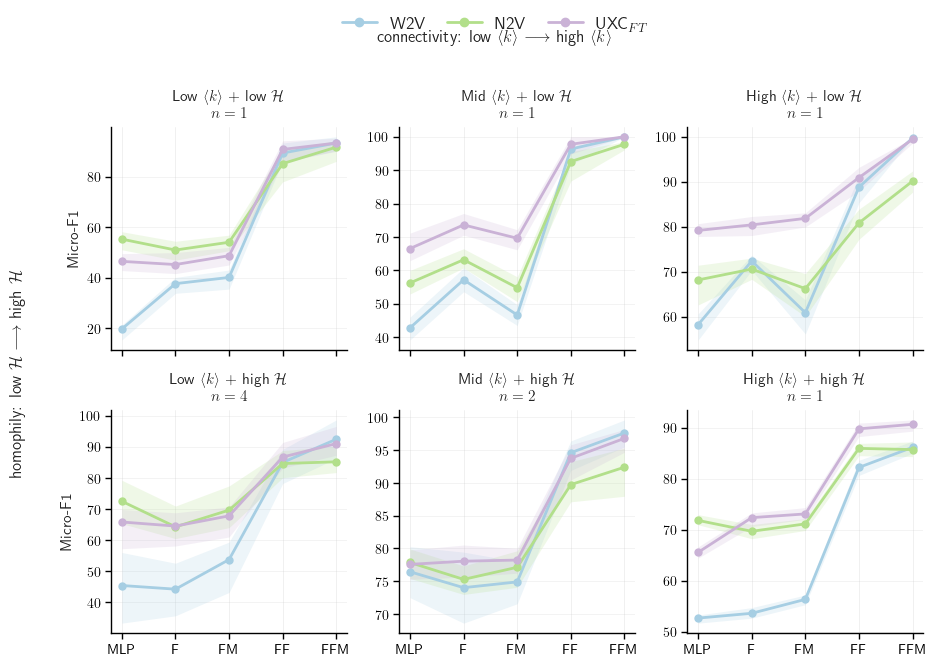

(<Figure size 900x600 with 6 Axes>,
 array([[<Axes: title={'center': 'Low $\\langle k \\rangle$ + low $\\mathcal{H}$\n$n=1$'}, ylabel='Micro-F1'>,
         <Axes: title={'center': 'Mid $\\langle k \\rangle$ + low $\\mathcal{H}$\n$n=1$'}>,
         <Axes: title={'center': 'High $\\langle k \\rangle$ + low $\\mathcal{H}$\n$n=1$'}>],
        [<Axes: title={'center': 'Low $\\langle k \\rangle$ + high $\\mathcal{H}$\n$n=4$'}, ylabel='Micro-F1'>,
         <Axes: title={'center': 'Mid $\\langle k \\rangle$ + high $\\mathcal{H}$\n$n=2$'}>,
         <Axes: title={'center': 'High $\\langle k \\rangle$ + high $\\mathcal{H}$\n$n=1$'}>]],
       dtype=object))

In [37]:
# --- Example: 2 (homophily) x 3 (avg_degree tertile) grid, 6 panels ---
# Reuses the same avg_degree_level tagging from the previous example cell, and
# tags homophily separately with the same tag_property_group helper -- no new
# tagging logic needed, just two independent calls. Labels use math text again so
# panel titles render as 'Low <k> + low H' etc., matching the original figure style.
homophily_thresholds = [0.5]
homophily_labels = [r'low $\mathcal{H}$', r'high $\mathcal{H}$']

tag_property_group(
    RQ2_LINEPLOT_DATA, DATASETS, 'homophily_level',
    'homophily', homophily_thresholds, homophily_labels,
)

for h_label in homophily_labels:
    for k_label in avg_degree_labels:
        systems = sorted(
            d for d in DATASETS
            if (
                (h_label == homophily_labels[0] and SYSTEM_PROPERTIES[d]['homophily'] < homophily_thresholds[0])
                or (h_label == homophily_labels[1] and SYSTEM_PROPERTIES[d]['homophily'] >= homophily_thresholds[0])
            )
            and (
                (k_label == avg_degree_labels[0] and SYSTEM_PROPERTIES[d]['avg_degree'] < avg_degree_thresholds[0])
                or (k_label == avg_degree_labels[1] and avg_degree_thresholds[0] <= SYSTEM_PROPERTIES[d]['avg_degree'] < avg_degree_thresholds[1])
                or (k_label == avg_degree_labels[2] and SYSTEM_PROPERTIES[d]['avg_degree'] >= avg_degree_thresholds[1])
            )
        )
        print(f'{h_label} x {k_label} (n={len(systems)}): {systems}')

aggregate_dual_group_subplots(
    data=RQ2_LINEPLOT_DATA,
    metrics=['f1_micro'],
    condition_order=RQ2_CONDITIONS,
    row_column='homophily_level',
    row_groups=homophily_labels,
    col_column='avg_degree_level',
    col_groups=avg_degree_labels,
    size=(9, 6),
    save_path=fig_path('RQ2_homophily_x_avg_degree_3level.pdf'),
    metric_labels=METRIC_LABELS,
    col_axis_label=r'connectivity: low $\langle k \rangle$ $\longrightarrow$ high $\langle k \rangle$',
    row_axis_label=r'homophily: low $\mathcal{H}$ $\longrightarrow$ high $\mathcal{H}$',
)

Low $\langle k \rangle$ (n=5): ['A.UML', 'Bash', 'C.Img', 'HDC', 'HDF']
High $\langle k \rangle$ (n=5): ['Chrome', 'JabRef', 'Lucene', 'SH-3D', 'T.Mates']


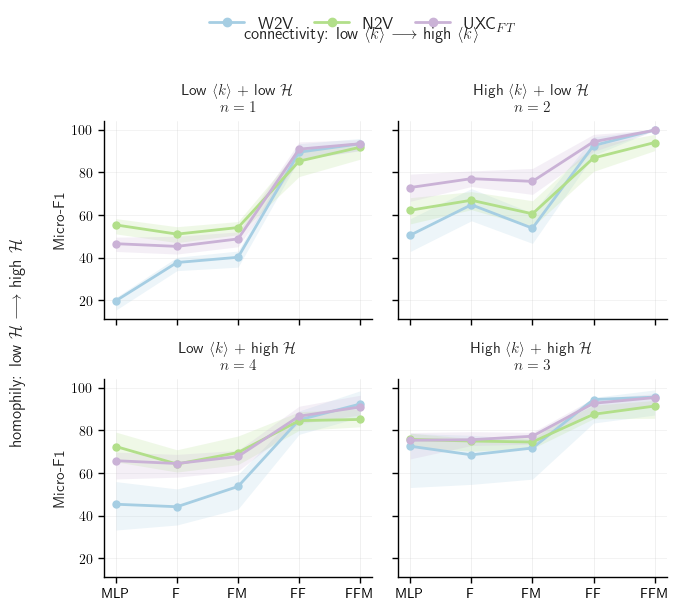

(<Figure size 650x550 with 4 Axes>,
 array([[<Axes: title={'center': 'Low $\\langle k \\rangle$ + low $\\mathcal{H}$\n$n=1$'}, ylabel='Micro-F1'>,
         <Axes: title={'center': 'High $\\langle k \\rangle$ + low $\\mathcal{H}$\n$n=2$'}>],
        [<Axes: title={'center': 'Low $\\langle k \\rangle$ + high $\\mathcal{H}$\n$n=4$'}, ylabel='Micro-F1'>,
         <Axes: title={'center': 'High $\\langle k \\rangle$ + high $\\mathcal{H}$\n$n=3$'}>]],
       dtype=object))

In [38]:
# --- 2x2 grid: homophily x connectivity, all 10 systems, one threshold ---
# Fixed to tag a genuine two-way split (not a subset of the 3-tier tag above), using
# the same CONNECTIVITY_THRESHOLD (13.0) already used for the main
# homophily_connectivity_quadrants.pdf figure -- one connectivity threshold, not three.
# Labels use math text so titles render as 'Low <k> + low H' etc.
avg_degree_binary_labels = [r'Low $\langle k \rangle$', r'High $\langle k \rangle$']

tag_property_group(
    RQ2_LINEPLOT_DATA, DATASETS, 'avg_degree_binary',
    'avg_degree', [CONNECTIVITY_THRESHOLD], avg_degree_binary_labels,
)

for k_label in avg_degree_binary_labels:
    systems = sorted(
        d for d in DATASETS
        if (
            (k_label == avg_degree_binary_labels[0] and SYSTEM_PROPERTIES[d]['avg_degree'] < CONNECTIVITY_THRESHOLD)
            or (k_label == avg_degree_binary_labels[1] and SYSTEM_PROPERTIES[d]['avg_degree'] >= CONNECTIVITY_THRESHOLD)
        )
    )
    print(f'{k_label} (n={len(systems)}): {systems}')

aggregate_dual_group_subplots(
    data=RQ2_LINEPLOT_DATA,
    metrics=['f1_micro'],
    condition_order=RQ2_CONDITIONS,
    row_column='homophily_level',
    row_groups=homophily_labels,
    col_column='avg_degree_binary',
    col_groups=avg_degree_binary_labels,
    size=(6.5, 5.5),
    save_path=fig_path('RQ2_homophily_x_avg_degree_2level_sharey.pdf'),
    metric_labels=METRIC_LABELS,
    col_axis_label=r'connectivity: low $\langle k \rangle$ $\longrightarrow$ high $\langle k \rangle$',
    row_axis_label=r'homophily: low $\mathcal{H}$ $\longrightarrow$ high $\mathcal{H}$',
    share_y=True,
)

---
## 6. RQ3 — Full controlled study (3,600 fits)

Ten systems x 3 embedding seeds x 10 splits x 12 fits, Node2Vec embeddings, file-level graph only.
Each comparison switches **one** thing: cross-file messages on/off (typed HGT; matched bidirectional-untyped HGT) or a neighbour block vs a zero block (MLP), under supervised-only and self-training schedules of equal length (190 epochs).

Per system and comparison there are 30 treatment fits and 30 control fits (3 seeds x 10 splits).
- **Effect** (as in the paper): median over splits within each seed, then the median of the three seed medians, in percentage points, with the seed range.
- **Mann-Whitney U / Cliff's delta**: treatment vs control, unpaired, Holm over all 60 tests per metric.
- **Wilcoxon signed-rank** on the 30 paired differences, as a sensitivity check (the arms share seed and split).
- **Sign test** across the 10 systems (and without A.UML): does not depend on overlapping splits.

In [40]:
wide = {m: full.pivot_table(index=['dataset', 'feature_seed', 'run_id'], columns='condition', values=m)
        for m in SCORE_COLS}

def paired_row(metric, ds, treat, ctrl):
    """Statistics for one system: treatment condition `treat` vs control condition `ctrl` (both full-study condition names)."""
    w = wide[metric].xs(ds, level='dataset')
    a, b = w[treat], w[ctrl]
    d = a - b                                              # paired by (seed, split)
    seed_med = d.groupby(level='feature_seed').median()
    stat, p, cd, interp = mw_test(a.values, b.values)
    try:
        wp = float(wilcoxon(d.values, zero_method='wilcox').pvalue) if (d != 0).any() else 1.0
    except ValueError:
        wp = 1.0
    return {
        'metric': metric, 'dataset': ds,
        'treatment med%': round(a.median(), 2), 'control med%': round(b.median(), 2),
        'paired_effect_pp': float(seed_med.median()),
        'seed_min_pp': float(seed_med.min()), 'seed_max_pp': float(seed_med.max()),
        'median_paired_diff_pp': float(d.median()),
        'stat': round(stat, 3), '_p': p, "Cliff's d": round(cd, 3), 'effect': interp, '_wp': wp,
    }

def paired_stat_table(specs, metrics=SCORE_COLS):
    """specs: list of dicts(family, schedule, comparison, treat, ctrl). Holm within metric over the whole table."""
    out = []
    for metric in metrics:
        rows = []
        for sp in specs:
            for ds in DATASET_ORDER:
                r = paired_row(metric, ds, sp['treat'], sp['ctrl'])
                r.update({k: sp[k] for k in ('family', 'schedule', 'comparison')})
                rows.append(r)
        adj, wadj = holm([r['_p'] for r in rows]), holm([r['_wp'] for r in rows])
        for r, pa, wa in zip(rows, adj, wadj):
            r['sig'] = '*' if r['_p'] < ALPHA else ''
            r['sig_holm'] = '*' if pa < ALPHA else ''
            r['p'], r['p_holm'] = f"{r.pop('_p'):.4f}", f"{pa:.4f}"
            r['wilcoxon_p'], r['wilcoxon_p_holm'] = f"{r.pop('_wp'):.4f}", f"{wa:.4f}"
            r['sig_wilcoxon_holm'] = '*' if wa < ALPHA else ''
        out.extend(rows)
    cols = ['metric', 'family', 'schedule', 'comparison', 'dataset', 'treatment med%', 'control med%',
            'paired_effect_pp', 'seed_min_pp', 'seed_max_pp', 'median_paired_diff_pp',
            'stat', 'p', 'p_holm', 'sig', 'sig_holm', "Cliff's d", 'effect',
            'wilcoxon_p', 'wilcoxon_p_holm', 'sig_wilcoxon_holm']
    return pd.DataFrame(out)[cols]

# primary: propagation / neighbour block on minus off, per schedule
primary_specs = []
for fam, (t_tpl, c_tpl) in RQ3_COMPARISONS.items():
    for s in SCHEDULES:
        t, c = t_tpl.format(s=s), c_tpl.format(s=s)
        primary_specs.append(dict(family=fam, schedule=s, comparison=f'{t} vs {c}', treat=t, ctrl=c))

rq3_stats = paired_stat_table(primary_specs)
save_stats(rq3_stats, 'rq3_stats.csv')
display(rq3_stats[rq3_stats.metric == 'f1_macro'].pivot_table(
    index='dataset', columns=['family', 'schedule'], values='paired_effect_pp').loc[DATASET_ORDER].round(2))

saved results\Statiscal_Test\rq3_stats.csv  (120 rows)


family   Matched HGT               Neighbour MLP               Typed HGT  \
schedule     self190 supervised190       self190 supervised190   self190   
dataset                                                                    
A.UML          -0.16          0.15          0.66          1.28    -10.14   
C.Img           0.47          1.58          2.28          0.60     -9.56   
JabRef          1.00          1.65          1.23          0.59     -2.38   
Lucene          0.10         -0.48          2.59          0.74     -8.51   
SH-3D          -1.15         -1.73          2.68          2.88     -1.12   
T.Mates         1.97          2.50          2.77          1.98     -1.90   
Bash           -0.01         -0.68          2.06          0.37     -2.97   
HDF             0.99          1.00          3.64          1.93     -4.78   
Chrome          0.45         -0.49          7.79          4.88     -6.61   
HDC            -0.87          0.65         -0.34         -0.89     -6.02   

family                  
schedule supervised190  
dataset                 
A.UML            -6.98  
C.Img            -9.18  
JabRef           -1.09  
Lucene           -7.01  
SH-3D            -2.73  
T.Mates           8.61  
Bash             -4.61  
HDF              -0.12  
Chrome           -6.89  
HDC              -7.30

In [41]:
# macro-F1: effect, Cliff's delta and Holm-significance side by side
t = rq3_stats[rq3_stats.metric == 'f1_macro'].copy()
t['cell'] = (t['paired_effect_pp'].map('{:+.2f}'.format) + ' (' + t['effect'].str[0].str.upper() + ')'
             + t['sig_holm'].map({'*': '*', '': ' ns'}))
display(t.pivot_table(index='dataset', columns=['family', 'schedule'], values='cell', aggfunc='first').loc[DATASET_ORDER])
print("(N/S/M/L = Cliff's delta magnitude; * = Holm-significant Mann-Whitney U, ns = not significant)")

family     Matched HGT               Neighbour MLP                \
schedule       self190 supervised190       self190 supervised190   
dataset                                                            
A.UML     -0.16 (N) ns  +0.15 (N) ns  +0.66 (N) ns  +1.28 (N) ns   
C.Img     +0.47 (S) ns  +1.58 (S) ns  +2.28 (S) ns  +0.60 (N) ns   
JabRef    +1.00 (S) ns  +1.65 (M) ns  +1.23 (S) ns  +0.59 (S) ns   
Lucene    +0.10 (N) ns  -0.48 (N) ns  +2.59 (M) ns  +0.74 (N) ns   
SH-3D     -1.15 (S) ns  -1.73 (S) ns  +2.68 (M) ns  +2.88 (S) ns   
T.Mates   +1.97 (S) ns  +2.50 (M) ns  +2.77 (M) ns  +1.98 (M) ns   
Bash      -0.01 (N) ns  -0.68 (N) ns  +2.06 (S) ns  +0.37 (N) ns   
HDF       +0.99 (N) ns  +1.00 (N) ns  +3.64 (M) ns  +1.93 (M) ns   
Chrome    +0.45 (N) ns  -0.49 (S) ns    +7.79 (L)*    +4.88 (L)*   
HDC       -0.87 (S) ns  +0.65 (N) ns  -0.34 (N) ns  -0.89 (N) ns   

family       Typed HGT                
schedule       self190 supervised190  
dataset                               
A.UML      -10.14 (L)*    -6.98 (L)*  
C.Img       -9.56 (L)*    -9.18 (L)*  
JabRef    -2.38 (S) ns  -1.09 (S) ns  
Lucene      -8.51 (L)*    -7.01 (L)*  
SH-3D     -1.12 (N) ns  -2.73 (S) ns  
T.Mates   -1.90 (N) ns    +8.61 (L)*  
Bash      -2.97 (L) ns    -4.61 (L)*  
HDF       -4.78 (L) ns  -0.12 (N) ns  
Chrome      -6.61 (L)*    -6.89 (L)*  
HDC         -6.02 (L)*    -7.30 (L)*

(N/S/M/L = Cliff's delta magnitude; * = Holm-significant Mann-Whitney U, ns = not significant)


In [42]:
# system-level sign tests: do the effects agree in sign across systems?
def sign_table(eff, drop=None):
    rows = []
    for (metric, fam, sch), g in eff.groupby(['metric', 'family', 'schedule'], sort=False):
        g = g[~g.dataset.isin(drop or [])]
        x = g['paired_effect_pp'].values
        npos, nneg = int((x > 0).sum()), int((x < 0).sum())
        p = binomtest(npos, npos + nneg, 0.5).pvalue if npos + nneg else 1.0
        rows.append({'metric': metric, 'family': fam, 'schedule': sch, 'systems': len(x),
                     'positive': npos, 'negative': nneg, 'zero': int((x == 0).sum()),
                     'median_effect_pp': round(float(np.median(x)), 2), '_p': p})
    out = pd.DataFrame(rows)
    out['p_sign'] = out['_p'].map('{:.4f}'.format)
    out['p_sign_holm'] = np.nan
    for m, idx in out.groupby('metric').groups.items():
        out.loc[idx, 'p_sign_holm'] = holm(out.loc[idx, '_p'])
    out['sig_sign_holm'] = np.where(out['p_sign_holm'] < ALPHA, '*', '')
    out['p_sign_holm'] = out['p_sign_holm'].map('{:.4f}'.format)
    return out.drop(columns='_p')

sign_all = sign_table(rq3_stats).assign(scope='all ten systems')
sign_noarg = sign_table(rq3_stats, drop=['A.UML']).assign(scope='excluding A.UML')
rq3_system_sign = pd.concat([sign_all, sign_noarg], ignore_index=True)
save_stats(rq3_system_sign, 'rq3_system_sign_tests.csv')
display(rq3_system_sign[rq3_system_sign.metric == 'f1_macro'])

saved results\Statiscal_Test\rq3_system_sign_tests.csv  (24 rows)


,metric,family,schedule,systems,positive,negative,zero,median_effect_pp,p_sign,p_sign_holm,sig_sign_holm,scope
0,f1_macro,Typed HGT,supervised190,10,1,9,0,-5.75,0.0215,0.1074,,all ten systems
1,f1_macro,Typed HGT,self190,10,0,10,0,-5.40,0.0020,0.0117,*,all ten systems
2,f1_macro,Matched HGT,supervised190,10,6,4,0,0.40,0.7539,1.0000,,all ten systems
3,f1_macro,Matched HGT,self190,10,6,4,0,0.27,0.7539,1.0000,,all ten systems
4,f1_macro,Neighbour MLP,supervised190,10,9,1,0,1.01,0.0215,0.1074,,all ten systems
5,f1_macro,Neighbour MLP,self190,10,9,1,0,2.44,0.0215,0.1074,,all ten systems
12,f1_macro,Typed HGT,supervised190,9,1,8,0,-4.61,0.0391,0.1953,,excluding A.UML
13,f1_macro,Typed HGT,self190,9,0,9,0,-4.78,0.0039,0.0234,*,excluding A.UML
14,f1_macro,Matched HGT,supervised190,9,5,4,0,0.65,1.0000,1.0000,,excluding A.UML
15,f1_macro,Matched HGT,self190,9,6,3,0,0.45,0.5078,1.0000,,excluding A.UML


In [43]:
# secondary: direct schedule contrasts, self-training minus supervised-only, model/features/graph held fixed
sched_specs = []
for fam, (t_tpl, c_tpl) in RQ3_COMPARISONS.items():
    for arm, tpl in (('treatment arm', t_tpl), ('control arm', c_tpl)):
        t, c = tpl.format(s='self190'), tpl.format(s='supervised190')
        sched_specs.append(dict(family=fam, schedule=arm, comparison=f'{t} vs {c}', treat=t, ctrl=c))
rq3_schedule_stats = paired_stat_table(sched_specs)
save_stats(rq3_schedule_stats, 'rq3_schedule_stats.csv')
display(rq3_schedule_stats[rq3_schedule_stats.metric == 'f1_macro'].pivot_table(
    index='dataset', columns=['family', 'schedule'], values='paired_effect_pp').loc[DATASET_ORDER].round(2))

saved results\Statiscal_Test\rq3_schedule_stats.csv  (120 rows)


family   Matched HGT               Neighbour MLP                 Typed HGT  \
schedule control arm treatment arm   control arm treatment arm control arm   
dataset                                                                      
A.UML          -1.14         -1.79         -1.98         -3.63       -1.14   
C.Img           1.48          1.03         -0.07          1.40        1.48   
JabRef          0.22         -1.15         -0.61         -0.60        0.22   
Lucene         -0.13          0.24         -2.42         -0.78       -0.13   
SH-3D          -9.40         -9.91         -7.21         -5.73       -9.40   
T.Mates        -4.41         -4.83         -7.54         -6.68       -4.41   
Bash           -6.59         -5.44         -3.71         -2.83       -6.59   
HDF            -1.74         -4.27         -2.82         -1.67       -1.74   
Chrome         -5.29         -4.36        -14.06         -9.96       -5.29   
HDC            -1.80         -4.14          0.22         -0.16       -1.80   

family                  
schedule treatment arm  
dataset                 
A.UML            -4.24  
C.Img            -0.46  
JabRef           -1.64  
Lucene           -1.13  
SH-3D            -7.34  
T.Mates         -12.63  
Bash             -5.82  
HDF              -6.95  
Chrome           -4.99  
HDC              -2.20

### RQ3 figures

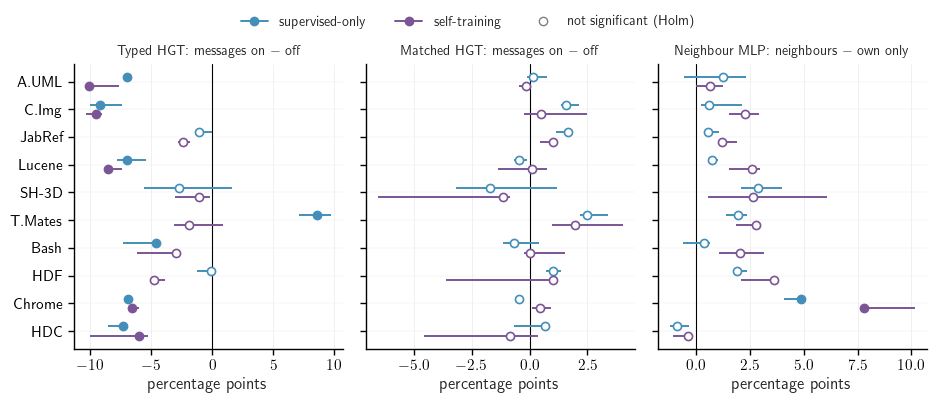

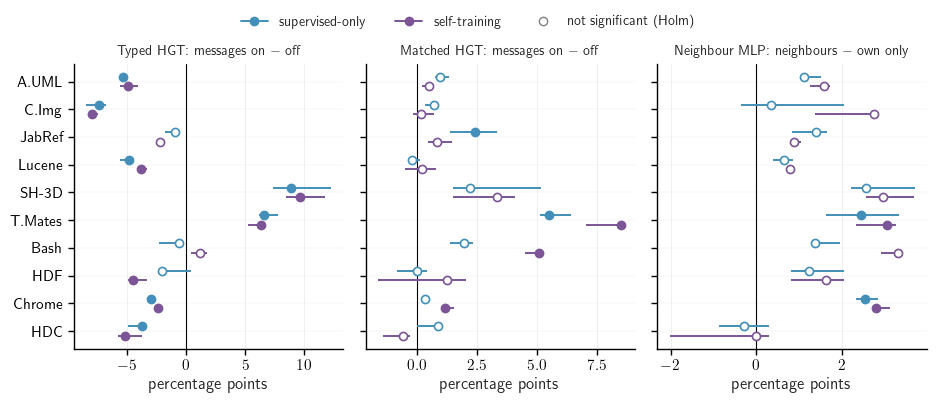

In [44]:
SCHED_COLOR = {'supervised190': '#438FB9', 'self190': '#7B5595'}
SCHED_LABEL = {'supervised190': 'supervised-only', 'self190': 'self-training'}
FAMILY_TITLE = {'Typed HGT': 'Typed HGT: messages on $-$ off',
                'Matched HGT': 'Matched HGT: messages on $-$ off',
                'Neighbour MLP': 'Neighbour MLP: neighbours $-$ own only'}

def effect_dotplot(eff, metric, save_path=None, size=(9.5, 3.8)):
    """Paired effect (median of 3 seed medians, pp) per system; bars = seed range; filled = Holm-significant Mann-Whitney U."""
    e = eff[eff.metric == metric]
    fams = list(RQ3_COMPARISONS)
    fig, axes = plt.subplots(1, len(fams), figsize=size, sharey=True, squeeze=False)
    ypos = {d: i for i, d in enumerate(DATASET_ORDER)}
    for ax, fam in zip(axes[0], fams):
        ax.axvline(0, color='black', linewidth=0.8, zorder=1)
        for si, sch in enumerate(SCHEDULES):
            off = (-0.17, 0.17)[si]
            g = e[(e.family == fam) & (e.schedule == sch)]
            for r in g.itertuples():
                y = ypos[r.dataset] + off
                ax.hlines(y, r.seed_min_pp, r.seed_max_pp, color=SCHED_COLOR[sch], linewidth=1.4, zorder=2)
                filled = r.sig_holm == '*'
                ax.scatter(r.paired_effect_pp, y, s=34, zorder=3, linewidth=1.2,
                           edgecolor=SCHED_COLOR[sch], facecolor=SCHED_COLOR[sch] if filled else 'white')
        ax.set_title(FAMILY_TITLE[fam], fontsize=10)
        ax.set_xlabel('percentage points')
        ax.set_yticks(range(len(DATASET_ORDER))); ax.set_yticklabels(DATASET_ORDER)
        ax.invert_yaxis(); ax.grid(axis='y', linewidth=0.3, alpha=0.4)
    from matplotlib.lines import Line2D
    handles = [Line2D([], [], marker='o', color=SCHED_COLOR[s], markerfacecolor=SCHED_COLOR[s], linewidth=1.4, label=SCHED_LABEL[s]) for s in SCHEDULES]
    handles.append(Line2D([], [], marker='o', color='grey', markerfacecolor='white', linestyle='', label='not significant (Holm)'))
    fig.legend(handles=handles, loc='upper center', ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.07), fontsize=10)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, bbox_inches='tight')
    plt.show()

effect_dotplot(rq3_stats, 'f1_macro', fig_path('RQ3_effects_f1_macro.pdf'))
effect_dotplot(rq3_stats, 'f1_micro', fig_path('RQ3_effects_f1_micro.pdf'))

---
## 7. Sanity checks

1. The paired effects reproduce the supervisor's digest.
2. The Mann-Whitney p-values agree with the old notebook's `scipy.stats.ranksums`.
3. Counts match the stated design.

In [45]:
def eff(metric, fam, sch, ds):
    r = rq3_stats[(rq3_stats.metric == metric) & (rq3_stats.family == fam) & (rq3_stats.schedule == sch) & (rq3_stats.dataset == ds)]
    return float(r.paired_effect_pp.iloc[0])

digest = [   # (metric, family, schedule, system, value from LLM_CONTEXT.md numerical digest)
    ('f1_macro', 'Typed HGT', 'self190', 'Lucene', -8.51),
    ('f1_macro', 'Typed HGT', 'self190', 'A.UML', -10.14),
    ('f1_macro', 'Typed HGT', 'supervised190', 'T.Mates', +8.61),
    ('f1_macro', 'Typed HGT', 'self190', 'T.Mates', -1.90),
    ('f1_micro', 'Matched HGT', 'self190', 'Bash', +5.08),
    ('f1_macro', 'Matched HGT', 'self190', 'Bash', -0.01),
    ('f1_macro', 'Matched HGT', 'self190', 'SH-3D', -1.15),
    ('f1_macro', 'Neighbour MLP', 'self190', 'Chrome', +7.79),
    ('f1_macro', 'Neighbour MLP', 'supervised190', 'Chrome', +4.88),
    ('f1_macro', 'Neighbour MLP', 'self190', 'HDC', -0.34),
]
for metric, fam, sch, ds, ref in digest:
    got = eff(metric, fam, sch, ds)
    assert abs(got - ref) < 0.006, (metric, fam, sch, ds, got, ref)
chrome_sched = rq3_schedule_stats[(rq3_schedule_stats.metric == 'f1_macro') & (rq3_schedule_stats.family == 'Neighbour MLP')
                                  & (rq3_schedule_stats.schedule == 'treatment arm') & (rq3_schedule_stats.dataset == 'Chrome')].paired_effect_pp.iloc[0]
assert abs(chrome_sched - (-9.96)) < 0.006, chrome_sched
print(f'OK: {len(digest) + 1} paired effects match the digest')

# sign counts from the digest: typed HGT macro negative on 10/10 (self) and 9/10 (supervised)
sg = rq3_system_sign[(rq3_system_sign.scope == 'all ten systems') & (rq3_system_sign.metric == 'f1_macro')].set_index(['family', 'schedule'])
assert sg.loc[('Typed HGT', 'self190'), 'negative'] == 10 and sg.loc[('Typed HGT', 'supervised190'), 'negative'] == 9
assert sg.loc[('Neighbour MLP', 'self190'), 'positive'] == 9 and sg.loc[('Neighbour MLP', 'supervised190'), 'positive'] == 9
print('OK: sign counts match the digest (typed HGT 10/10 and 9/10 negative; neighbour MLP 9/10 positive)')

# Mann-Whitney vs the old notebook's ranksums
from scipy.stats import ranksums
diffs = []
for label_a, label_b in [('W2V', 'N2V'), ('N2V', 'UXC$_{FT}$'), ('W2V', 'UXC$_{ZS}$')]:
    for ds in DATASET_ORDER:
        for m in SCORE_COLS:
            a = RQ1[label_a].loc[RQ1[label_a].dataset == ds, m].values
            b = RQ1[label_b].loc[RQ1[label_b].dataset == ds, m].values
            diffs.append(abs(mannwhitneyu(a, b, method='asymptotic').pvalue - ranksums(a, b).pvalue))
print(f'max |p_MWU - p_ranksums| over {len(diffs)} RQ1 tests: {max(diffs):.4f}')
print(f'tests where the 0.05 decision differs: ', sum(
    (mannwhitneyu(RQ1[a].loc[RQ1[a].dataset == ds, m].values, RQ1[b].loc[RQ1[b].dataset == ds, m].values, method="asymptotic").pvalue < 0.05)
    != (ranksums(RQ1[a].loc[RQ1[a].dataset == ds, m].values, RQ1[b].loc[RQ1[b].dataset == ds, m].values).pvalue < 0.05)
    for a, b in [('W2V', 'N2V'), ('N2V', 'UXC$_{FT}$'), ('W2V', 'UXC$_{ZS}$')] for ds in DATASET_ORDER for m in SCORE_COLS))

print('rows:', {'rq1_stats': len(rq1_stats), 'rq2_stats': len(rq2_stats), 'rq3_stats': len(rq3_stats),
                'rq3_schedule_stats': len(rq3_schedule_stats), 'rq3_system_sign_tests': len(rq3_system_sign)})

OK: 11 paired effects match the digest
OK: sign counts match the digest (typed HGT 10/10 and 9/10 negative; neighbour MLP 9/10 positive)
max |p_MWU - p_ranksums| over 60 RQ1 tests: 0.0009
tests where the 0.05 decision differs:  0
rows: {'rq1_stats': 132, 'rq2_stats': 660, 'rq3_stats': 120, 'rq3_schedule_stats': 120, 'rq3_system_sign_tests': 24}
